# QMB supplementary pipeline: preliminary campaign reproduction

Standalone companion to the main pipeline notebook. Running it top to
bottom from the raw datasets (local copies first, Kaggle download via
`kagglehub` otherwise) reproduces the experiments behind the paper's
Supplementary Material and its figures:

- E1: harmonized classical baselines (Supplementary Table S2)
- E2: paired knowledge-distillation statistics and training-dynamics
  figures (Supplementary Figure S2)
- E3: repeated measurement-budget realizations with both predictors
  (Supplementary Table S5, Supplementary Figure S1)
- E4: depth and circuit-seed sweep with alignment diagnostics
  (Supplementary Figure S5)
- E5: error analysis, confusion matrices, misclassified glyphs, class
  sheets, and the resolution ablation (Supplementary Figure S6, main
  Figure 11, Supplementary Figures S3 and S4, dataset overview)
- Q: the first hardware campaign's two-tier protocol (`QPU_MODE` is
  `"aer"` by default, a local noiseless rehearsal; set `"ibm-submit"`
  with credentials to submit) and that campaign's circuit drawing

The S1, S3, and S4 sections replicate the multi-run, control, and
single-run campaigns behind Supplementary Tables S1, S3, and S4; the
recorded values of the preliminary campaigns are printed at the end for
comparison against a re-run. The plotting style cell below enlarges
fonts so a re-run regenerates the supplementary figures at improved
legibility.

In [1]:
# ============================== CONFIG ==============================
IMG_SIZE = 32
DEPTH            = 4
MAX_PAULI_WEIGHT = 3
QMB_SEED         = 7

KC_EXPANSION = 10
FAN_IN_FRAC  = 0.12
KC_SPARSITY  = 0.05

LAMBDA_KD = 0.5
TAU       = 4.0

EPOCHS       = 40
BATCH_SIZE   = 64
LR           = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT      = 0.10
N_AUG        = 2
TEST_FRAC    = 0.2
VAL_FRAC     = 0.10            # E4 only: stratified validation carved from dev
SEED         = 42
SEEDS_RUN    = [42, 43, 44, 45, 46]

# --- section toggles ---
RUN_E1_BASELINES  = True
RUN_E2_KD_PAIRED  = True
RUN_E3_BUDGET     = True
RUN_E4_DEPTH      = True
RUN_E5_ERRORS     = True

E3_BUDGETS  = [512, 1024, 4096, 16384]
E3_REPEATS  = 10               # fixed-head sampling realizations per budget
E3_MC_DRAWS = 500              # Monte-Carlo draws for the covariance-aware predictor
E4_DEPTHS   = [1, 2, 3, 4, 6, 8]
E4_CIRCUIT_SEEDS = [7, 8, 9]
PROBE_SIZE  = 400
E5_RES_HI   = 64               # resolution ablation (classical teacher, Modi)

# --- QPU (Brahmi only) ---
QPU_MODE        = "aer"        # "aer" | "ibm-submit" | "ibm-retrieve" | "off"
QPU_SHOTS       = 1024
QPU_A_IMAGES    = 10           # tier A: n=10 characterization images
QPU_B_IMAGES    = 50           # tier B: n=8 classification images
QPU_B_IMG_SIZE  = 16           # tier B register: 16x16 -> n=8
QPU_JOBS_FILE   = "qpu_jobs.json"

DATASETS = {
    "Brahmi": {"slug": "gautamneha/brahmi-dataset", "folder": "kaggle-brahmi"},
    "Modi":   {"slug": "msd6013/modi-hdc-historical-handwritten-modi-script",
               "folder": "kaggle-modi", "prefer": "consonants",
               "merge": False, "max_per_class": 100},
}

import math
D_IN = IMG_SIZE * IMG_SIZE
assert (D_IN & (D_IN - 1)) == 0
N_QUBITS = int(math.log2(D_IN))
N_KC     = KC_EXPANSION * D_IN
FAN_IN   = max(6, round(FAN_IN_FRAC * D_IN))
K_ACTIVE = max(1, round(KC_SPARSITY * N_KC))
N_FEAT   = 3 * sum(math.comb(N_QUBITS, k) for k in range(1, MAX_PAULI_WEIGHT + 1))
print(f"D={D_IN} -> {N_QUBITS} qubits | {N_FEAT} features | teacher {N_KC} KCs")

D=1024 -> 10 qubits | 525 features | teacher 10240 KCs


In [2]:
import os, random, shutil, subprocess, time, json as _json
from pathlib import Path
from itertools import combinations

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


In [3]:
# plotting style for legible supplementary figures
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "figure.dpi": 110, "savefig.dpi": 220, "axes.grid": True,
    "grid.alpha": 0.25, "lines.linewidth": 1.6, "lines.markersize": 5.5,
})

## 0. Data (parameterized image size; local cache first)

[gautamneha/brahmi-dataset] using local cache: C:\Users\ashis\PycharmProjects\pythonProject1\kaggle-brahmi
[Brahmi@32px] 170 classes | train 4250 | test 850 | existing split (train/test)
[msd6013/modi-hdc-historical-handwritten-modi-script] using local cache: C:\Users\ashis\PycharmProjects\pythonProject1\kaggle-modi
[Modi@32px] 35 classes | train 2800 | test 700 | stratified 80/20 split
[Brahmi] effective training set: 12750
[Modi] effective training set: 8400


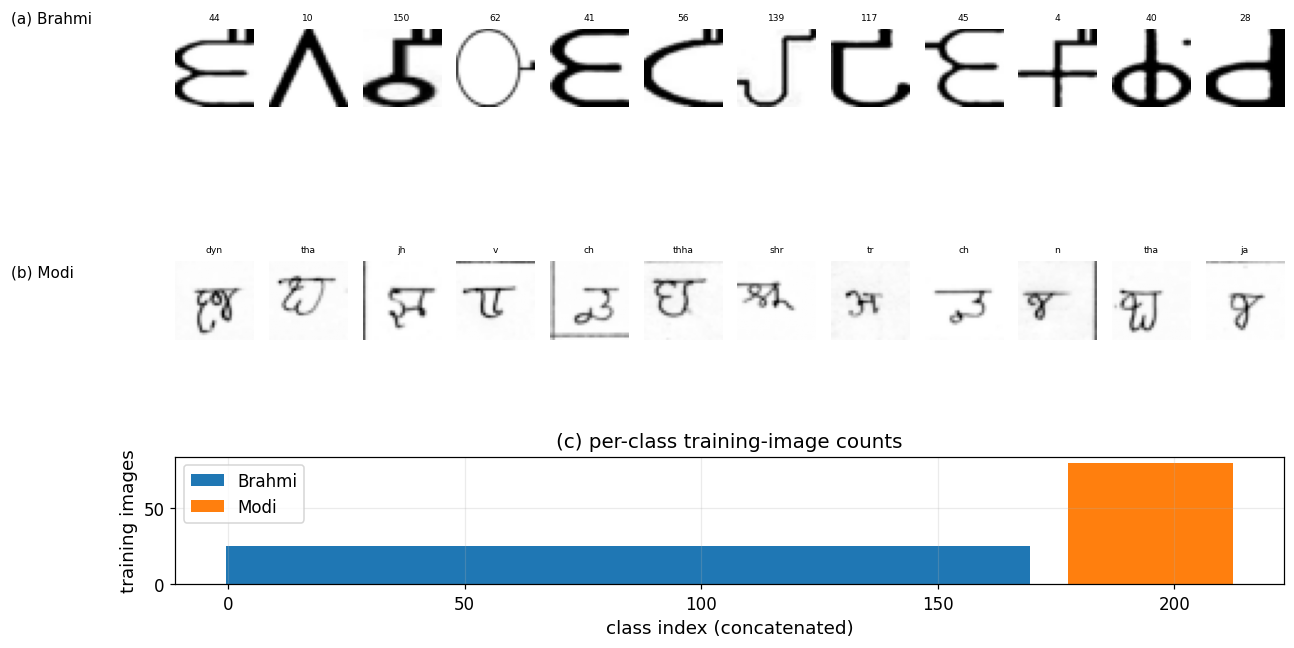

In [4]:
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".gif", ".webp"}

def folder_has_images(folder: Path) -> bool:
    return folder.is_dir() and any(p.suffix.lower() in IMG_EXTS for p in folder.rglob("*"))

def ensure_dataset(slug, folder):
    dest = Path(folder)
    if folder_has_images(dest):
        print(f"[{slug}] using local cache: {dest.resolve()}"); return dest
    dest.mkdir(parents=True, exist_ok=True)
    print(f"[{slug}] no local copy -> downloading ...")
    try:
        import kagglehub
        shutil.copytree(Path(kagglehub.dataset_download(slug)), dest, dirs_exist_ok=True)
    except Exception as e:
        print(f"kagglehub failed ({e}); trying kaggle CLI ...")
        subprocess.run(["kaggle", "datasets", "download", "-d", slug,
                        "-p", str(dest), "--unzip"], check=True)
    assert folder_has_images(dest), f"download of {slug} produced no images"
    return dest

def find_class_roots(root: Path):
    candidates = []
    for d in [root] + [p for p in root.rglob("*") if p.is_dir()]:
        subdirs = [s for s in d.iterdir() if s.is_dir()]
        if len(subdirs) >= 2 and all(
            any(f.suffix.lower() in IMG_EXTS for f in s.iterdir() if f.is_file())
            for s in subdirs[: min(len(subdirs), 5)]
        ):
            candidates.append((d, len(subdirs)))
    if not candidates:
        raise RuntimeError(f"no class-structured folders under {root}")
    candidates.sort(key=lambda t: (len(t[0].parts), t[1]), reverse=True)
    roots, seen = [], set()
    for d, _ in candidates:
        if not any(str(d) in str(r) or str(r) in str(d) for r in seen):
            roots.append(d); seen.add(d)
    return roots

def load_split_arrays(class_root, classes=None, frac=1.0, max_per_class=None,
                      img_size=IMG_SIZE):
    if classes is None:
        classes = sorted([s.name for s in class_root.iterdir() if s.is_dir()])
    cls_to_idx = {c: i for i, c in enumerate(classes)}
    X, y = [], []
    for ci, c in enumerate(classes):
        cdir = class_root / c
        if not cdir.is_dir(): continue
        files = [f for f in sorted(cdir.rglob("*")) if f.suffix.lower() in IMG_EXTS]
        rng = random.Random(SEED + ci)
        rng.shuffle(files)
        n_keep = len(files)
        if frac < 1.0: n_keep = max(1, int(round(frac * len(files))))
        if max_per_class is not None: n_keep = min(n_keep, max_per_class)
        for f in files[:n_keep]:
            im = Image.open(f).convert("L").resize((img_size, img_size), Image.BILINEAR)
            X.append(np.asarray(im, dtype=np.float32) / 255.0)
            y.append(cls_to_idx[c])
    return torch.from_numpy(np.stack(X)).unsqueeze(1), torch.tensor(y, dtype=torch.long), classes

def stratified_indices(y, n_classes, frac, seed):
    g = torch.Generator().manual_seed(seed); a_idx, b_idx = [], []
    for c in range(n_classes):
        idx = (y == c).nonzero(as_tuple=True)[0]
        idx = idx[torch.randperm(len(idx), generator=g)]
        n_b = max(1, int(round(frac * len(idx))))
        b_idx.append(idx[:n_b]); a_idx.append(idx[n_b:])
    return torch.cat(a_idx), torch.cat(b_idx)

def build_dataset(name, root, prefer=None, frac=1.0, max_per_class=None,
                  merge=False, img_size=IMG_SIZE):
    roots = find_class_roots(root)
    if prefer:
        hits = [r for r in roots if prefer.lower() in str(r).lower()]
        if hits: roots = hits
        else: print(f"[{name}] note: no folder matches prefer='{prefer}'")
    tr = next((r for r in roots if "train" in str(r).lower()), None)
    te = next((r for r in roots if any(k in str(r).lower() for k in ("test", "val"))), None)
    if tr is not None and te is not None and tr != te:
        Xtr, ytr, classes = load_split_arrays(tr, frac=frac, max_per_class=max_per_class,
                                              img_size=img_size)
        Xte, yte, _ = load_split_arrays(te, classes, frac=frac, max_per_class=max_per_class,
                                        img_size=img_size)
        src = f"existing split ({tr.name}/{te.name})"
    else:
        X, y, classes = load_split_arrays(roots[0], frac=frac, max_per_class=max_per_class,
                                          img_size=img_size)
        tr_i, te_i = stratified_indices(y, len(classes), TEST_FRAC, SEED)
        Xtr, ytr, Xte, yte = X[tr_i], y[tr_i], X[te_i], y[te_i]
        src = f"stratified {int((1-TEST_FRAC)*100)}/{int(TEST_FRAC*100)} split"
    print(f"[{name}@{img_size}px] {len(classes)} classes | train {len(ytr)} | "
          f"test {len(yte)} | {src}")
    return {"Xtr": Xtr, "ytr": ytr, "Xte": Xte, "yte": yte, "classes": classes}

DATA = {name: build_dataset(name, ensure_dataset(c["slug"], c["folder"]),
                            c.get("prefer"), c.get("frac", 1.0),
                            c.get("max_per_class"), c.get("merge", False))
        for name, c in DATASETS.items()}

def augment(X, gen):
    out = X.clone()
    for i in range(len(out)):
        dx = int(torch.randint(-2, 3, (1,), generator=gen))
        dy = int(torch.randint(-2, 3, (1,), generator=gen))
        out[i] = torch.roll(out[i], shifts=(dy, dx), dims=(1, 2))
    return (out + 0.03 * torch.randn(out.shape, generator=gen)).clamp(0, 1)

def augmented(X, y, n_aug=N_AUG, seed=SEED + 1):
    if n_aug <= 0: return X, y
    g = torch.Generator().manual_seed(seed)
    Xa = torch.cat([X] + [augment(X, g) for _ in range(n_aug)])
    return Xa, y.repeat(n_aug + 1)

for name, d in DATA.items():
    d["Xtr_a"], d["ytr_a"] = augmented(d["Xtr"], d["ytr"])
    print(f"[{name}] effective training set: {len(d['ytr_a'])}")

# --- manuscript Figure (fig:datasets): sample glyphs + class balance ---
fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(3, 12, height_ratios=[1.2, 1.2, 1.0], hspace=0.55)
for row, name in enumerate(DATA):
    d = DATA[name]
    idx = torch.randperm(len(d["ytr"]),
                         generator=torch.Generator().manual_seed(3))[:12]
    for col, i in enumerate(idx):
        ax = fig.add_subplot(gs[row, col])
        ax.imshow(d["Xtr"][i, 0], cmap="gray"); ax.axis("off")
        ax.set_title(d["classes"][d["ytr"][i]], fontsize=6)
    fig.text(0.01, 0.84 - 0.33 * row, f"({chr(97+row)}) {name}", fontsize=10)
axc = fig.add_subplot(gs[2, :])
offs = 0
for name, d in DATA.items():
    cnt = torch.bincount(d["ytr"], minlength=len(d["classes"])).numpy()
    axc.bar(np.arange(len(cnt)) + offs, cnt, width=1.0, label=name)
    offs += len(cnt) + 8
axc.set_xlabel("class index (concatenated)"); axc.set_ylabel("training images")
axc.set_title("(c) per-class training-image counts"); axc.legend()
plt.savefig("fig_datasets.png", dpi=200, bbox_inches="tight"); plt.show()

## 1. Models and training utilities

In [5]:
def pn_normalize(X):
    x = X.flatten(1)
    x = x - x.mean(dim=1, keepdim=True)
    nrm = x.norm(dim=1, keepdim=True)
    return torch.where(nrm > 1e-8, x / nrm, torch.full_like(x, 1 / math.sqrt(x.shape[1])))

class FlyMushroomBodyNet(nn.Module):
    def __init__(self, in_dim, n_classes, n_kc=None, fan_in=None,
                 sparsity=KC_SPARSITY, seed=SEED, normalized_input=False):
        super().__init__()
        n_kc = n_kc or KC_EXPANSION * in_dim
        fan_in = fan_in or max(6, round(FAN_IN_FRAC * in_dim))
        self.k_active = max(1, round(sparsity * n_kc))
        self.normalized_input = normalized_input
        g = torch.Generator().manual_seed(seed)
        proj = torch.zeros(n_kc, in_dim)
        for i in range(n_kc):
            proj[i, torch.randperm(in_dim, generator=g)[:fan_in]] = 1.0
        self.register_buffer("proj", proj / math.sqrt(fan_in))
        self.readout = nn.Linear(n_kc, n_classes)
    def kc_code(self, x):
        if self.normalized_input:
            x = pn_normalize(x)
        else:
            x = x.flatten(1); x = x - x.mean(dim=1, keepdim=True)
        kc = F.linear(x, self.proj)
        topv, topi = kc.topk(self.k_active, dim=1)
        return torch.zeros_like(kc).scatter_(1, topi, F.relu(topv))
    def forward(self, x): return self.readout(self.kc_code(x))

def random_su4(gen):
    z = torch.randn(4, 4, generator=gen, dtype=torch.float64) \
        + 1j * torch.randn(4, 4, generator=gen, dtype=torch.float64)
    q, r = torch.linalg.qr(z)
    d = torch.diagonal(r)
    return (q * (d / d.abs())).contiguous().to(torch.complex64)

def build_brickwork(n_qubits, depth, seed):
    gen = torch.Generator().manual_seed(seed)
    dim = 2 ** n_qubits
    U = torch.eye(dim, dtype=torch.complex64)
    I2 = torch.eye(2, dtype=torch.complex64)
    gates = []
    for layer in range(depth):
        pairs = [(i, i + 1) for i in range(layer % 2, n_qubits - 1, 2)]
        L = torch.eye(1, dtype=torch.complex64); q = 0
        while q < n_qubits:
            if pairs and pairs[0][0] == q:
                M = random_su4(gen); gates.append(((q, q + 1), M))
                L = torch.kron(L, M); pairs.pop(0); q += 2
            else:
                L = torch.kron(L, I2); q += 1
        U = L @ U
    return U, gates

H_1 = torch.tensor([[1, 1], [1, -1]], dtype=torch.complex64) / math.sqrt(2)
HSd = torch.tensor([[1, -1j], [1, 1j]], dtype=torch.complex64) / math.sqrt(2)

def kron_n(M, n):
    out = torch.eye(1, dtype=torch.complex64)
    for _ in range(n): out = torch.kron(out, M)
    return out

def pauli_subsets(n_qubits, max_w):
    return [s for w in range(1, max_w + 1) for s in combinations(range(n_qubits), w)]

def subset_mask(S, n):     # qubit 0 = MSB convention (matches basis-index integers)
    return sum(1 << (n - 1 - r) for r in S)

def character_matrix(n_qubits, subsets):
    dim = 2 ** n_qubits
    b = torch.arange(dim)
    bits = ((b.unsqueeze(1) >> torch.arange(n_qubits - 1, -1, -1)) & 1)
    C = torch.empty(len(subsets), dim)
    for j, S in enumerate(subsets):
        C[j] = 1.0 - 2.0 * (bits[:, list(S)].sum(1) % 2)
    return C

def fwht(p):
    """Fast Walsh--Hadamard transform over the last dim (len = power of 2).
    Returns all parities: out[..., s] = sum_v (-1)^{popcount(s&v)} p[..., v]."""
    y = p.clone()
    D = y.shape[-1]; h = 1
    while h < D:
        y = y.view(*y.shape[:-1], D // (2 * h), 2, h)
        a = y[..., 0, :] + y[..., 1, :]
        b = y[..., 0, :] - y[..., 1, :]
        y = torch.stack((a, b), dim=-2).reshape(*a.shape[:-2], D)
        h *= 2
    return y

def sample_dist(p, shots, gen):
    s = torch.multinomial(p, shots, replacement=True, generator=gen)
    return torch.zeros_like(p).scatter_add_(
        1, s, torch.ones(s.shape, dtype=p.dtype)) / shots

class QuantumMushroomBody:
    def __init__(self, n_qubits=N_QUBITS, depth=DEPTH, max_w=MAX_PAULI_WEIGHT,
                 seed=QMB_SEED):
        self.n, self.depth, self.seed = n_qubits, depth, seed
        self.U, self.gates = build_brickwork(n_qubits, depth, seed)
        self.R = {"Z": None, "X": kron_n(H_1, n_qubits), "Y": kron_n(HSd, n_qubits)}
        self.subsets = pauli_subsets(n_qubits, max_w)
        self.masks = torch.tensor([subset_mask(S, n_qubits) for S in self.subsets])
        self.C = character_matrix(n_qubits, self.subsets)
        self.n_features = 3 * len(self.subsets)
    def probs(self, X, batch=256):
        """Yield (slice, {basis: outcome probabilities}) per batch."""
        for i in range(0, len(X), batch):
            psi = pn_normalize(X[i:i + batch]).to(torch.complex64) @ self.U.T
            P = {}
            for basis in ("Z", "X", "Y"):
                phi = psi if self.R[basis] is None else psi @ self.R[basis].T
                P[basis] = phi.abs() ** 2
            yield slice(i, i + len(P["Z"])), P
    def features(self, X, shots=None, batch=256, gen=None):
        out = torch.empty(len(X), self.n_features)
        for sl, P in self.probs(X, batch):
            fs = []
            for basis in ("Z", "X", "Y"):
                p = P[basis]
                if shots is not None:
                    p = sample_dist(p, shots, gen)
                fs.append(p @ self.C.T)
            out[sl] = torch.cat(fs, dim=1)
        return out

class RandomQuadraticFeatures:
    def __init__(self, in_dim, n_features=N_FEAT, seed=1234, chunk=8):
        self.in_dim, self.n_features, self.seed, self.chunk = in_dim, n_features, seed, chunk
    def features(self, X, batch=512):
        Xn = pn_normalize(X)
        out = torch.empty(len(Xn), self.n_features)
        for cstart in range(0, self.n_features, self.chunk):
            k = min(self.chunk, self.n_features - cstart)
            g = torch.Generator().manual_seed(self.seed + cstart)
            A = torch.randn(k, self.in_dim, self.in_dim, generator=g)
            for i in range(0, len(Xn), batch):
                xb = Xn[i:i + batch]
                t = torch.einsum('bd,kde->bke', xb, A)
                out[i:i + batch, cstart:cstart + k] = (t * xb.unsqueeze(1)).sum(-1)
        return out

class MBONHead(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(n_features, n_classes))
    def forward(self, f): return self.net(f)

def macro_f1(y_true, y_pred, n_classes):
    f1s = []
    for c in range(n_classes):
        tp = ((y_pred == c) & (y_true == c)).sum().item()
        fp = ((y_pred == c) & (y_true != c)).sum().item()
        fn = ((y_pred != c) & (y_true == c)).sum().item()
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * p * r / (p + r) if p + r else 0.0)
    return float(np.mean(f1s))

@torch.no_grad()
def eval_batched(model, X, y):
    model.eval(); preds = []
    for i in range(0, len(y), 512):
        preds.append(model(X[i:i + 512].to(DEVICE)).argmax(1).cpu())
    preds = torch.cat(preds)
    return (preds == y).float().mean().item(), preds

def train_model(model, Xtr, ytr, Xte, yte, n_classes, tag,
                teacher=None, teacher_inputs=None, epochs=EPOCHS, verbose=False):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    hist = {"loss": [], "train_acc": [], "test_acc": []}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(ytr))
        loss_s, corr = 0.0, 0
        for i in range(0, len(perm), BATCH_SIZE):
            sel = perm[i:i + BATCH_SIZE]
            xb, yb = Xtr[sel].to(DEVICE), ytr[sel].to(DEVICE)
            opt.zero_grad()
            out = model(xb)
            loss = F.cross_entropy(out, yb)
            if teacher is not None:
                with torch.no_grad():
                    t = teacher(teacher_inputs[sel].to(DEVICE))
                kd = F.kl_div(F.log_softmax(out / TAU, 1),
                              F.softmax(t / TAU, 1), reduction="batchmean") * TAU ** 2
                loss = (1 - LAMBDA_KD) * loss + LAMBDA_KD * kd
            loss.backward(); opt.step()
            loss_s += loss.item() * len(yb)
            corr += (out.argmax(1) == yb).sum().item()
        te_acc, _ = eval_batched(model, Xte, yte)
        hist["loss"].append(loss_s / len(perm))
        hist["train_acc"].append(corr / len(perm))
        hist["test_acc"].append(te_acc)
        if verbose and ((ep + 1) % 10 == 0 or ep == 0):
            print(f"  [{tag}] epoch {ep+1:3d} | loss {hist['loss'][-1]:.3f} | "
                  f"train {hist['train_acc'][-1]:.3f} | test {te_acc:.3f}")
    acc, preds = eval_batched(model, Xte, yte)
    model._hist = hist
    return model, preds, acc, macro_f1(yte, preds, n_classes)

def standardize(Ftr, Fte):
    mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-8
    return (Ftr - mu) / sd, (Fte - mu) / sd, mu, sd

def msd(vals):   # mean ± sample std (ddof=1, as the Experimental Setup specifies)
    a = np.array(vals, dtype=float)
    return a.mean(), (a.std(ddof=1) if len(a) > 1 else 0.0)

qmb = QuantumMushroomBody()
FEATS = {}
for name, d in DATA.items():
    Ftr_raw, Fte_raw = qmb.features(d["Xtr_a"]), qmb.features(d["Xte"])
    Ftr, Fte, mu, sd = standardize(Ftr_raw, Fte_raw)
    FEATS[name] = dict(Ftr=Ftr, Fte=Fte, Fte_raw=Fte_raw, mu=mu, sd=sd)
    print(f"[{name}] exact QMB features cached")

[Brahmi] exact QMB features cached
[Modi] exact QMB features cached


## E1: Harmonized classical baselines (5 seeds)
`FlyMB-525` in its original protocol, plus harmonized variants of both classical MB models:
unit-norm inputs, feature standardization, and the same dropout head as QMB/RandQuad.

In [6]:
E1 = {}
if RUN_E1_BASELINES:
    for name, d in DATA.items():
        n_classes = len(d["classes"])
        Xa, ya, Xte, yte = d["Xtr_a"], d["ytr_a"], d["Xte"], d["yte"]
        for variant, n_kc in [("FlyMB-525", N_FEAT), ("Teacher", N_KC)]:
            orig, harm = [], []
            for s in SEEDS_RUN:
                torch.manual_seed(s)                       # original protocol
                m0 = FlyMushroomBodyNet(D_IN, n_classes, n_kc=n_kc, seed=s)
                _, _, a, f1 = train_model(m0, Xa, ya, Xte, yte, n_classes,
                                          f"{name}/{variant}/orig/s{s}")
                orig.append((a, f1))
                torch.manual_seed(s)                       # harmonized protocol
                fx = FlyMushroomBodyNet(D_IN, n_classes, n_kc=n_kc, seed=s,
                                        normalized_input=True)
                with torch.no_grad():
                    Htr = torch.cat([fx.kc_code(Xa[i:i+512]) for i in range(0, len(ya), 512)])
                    Hte = torch.cat([fx.kc_code(Xte[i:i+512]) for i in range(0, len(yte), 512)])
                Htr, Hte, _, _ = standardize(Htr, Hte)
                h = MBONHead(n_kc, n_classes)
                _, _, a, f1 = train_model(h, Htr, ya, Hte, yte, n_classes,
                                          f"{name}/{variant}/harm/s{s}")
                harm.append((a, f1))
            for tag, vals in [("original", orig), ("harmonized", harm)]:
                ma, sa = msd([v[0] for v in vals]); mf, sf = msd([v[1] for v in vals])
                E1[(name, variant, tag)] = (ma, sa, mf, sf)
                print(f"[E1 {name}] {variant:<10} {tag:<11} "
                      f"acc {ma:.4f} ± {sa:.4f} | F1 {mf:.4f} ± {sf:.4f}")

[E1 Brahmi] FlyMB-525  original    acc 0.9289 ± 0.0071 | F1 0.9274 ± 0.0077
[E1 Brahmi] FlyMB-525  harmonized  acc 0.9304 ± 0.0057 | F1 0.9285 ± 0.0058
[E1 Brahmi] Teacher    original    acc 0.9579 ± 0.0034 | F1 0.9551 ± 0.0040
[E1 Brahmi] Teacher    harmonized  acc 0.9379 ± 0.0144 | F1 0.9335 ± 0.0179
[E1 Modi] FlyMB-525  original    acc 0.1263 ± 0.0064 | F1 0.1119 ± 0.0088
[E1 Modi] FlyMB-525  harmonized  acc 0.1123 ± 0.0117 | F1 0.1106 ± 0.0120
[E1 Modi] Teacher    original    acc 0.2797 ± 0.0092 | F1 0.2754 ± 0.0107
[E1 Modi] Teacher    harmonized  acc 0.2886 ± 0.0138 | F1 0.2825 ± 0.0139


## E2: Paired KD statistics (per-run predictions, sign counts)

[E2 Brahmi] seed 42: teacher 0.9600 | QMB 0.9635 | +KD 0.9588 | diff -0.0047
[E2 Brahmi] seed 43: teacher 0.9576 | QMB 0.9612 | +KD 0.9647 | diff +0.0035
[E2 Brahmi] seed 44: teacher 0.9541 | QMB 0.9635 | +KD 0.9624 | diff -0.0012
[E2 Brahmi] seed 45: teacher 0.9624 | QMB 0.9600 | +KD 0.9600 | diff +0.0000
[E2 Brahmi] seed 46: teacher 0.9553 | QMB 0.9600 | +KD 0.9565 | diff -0.0035
[E2 Brahmi] KD−noKD = -0.0012 ± 0.0032 | positive 1/5 | Wilcoxon p = 0.625


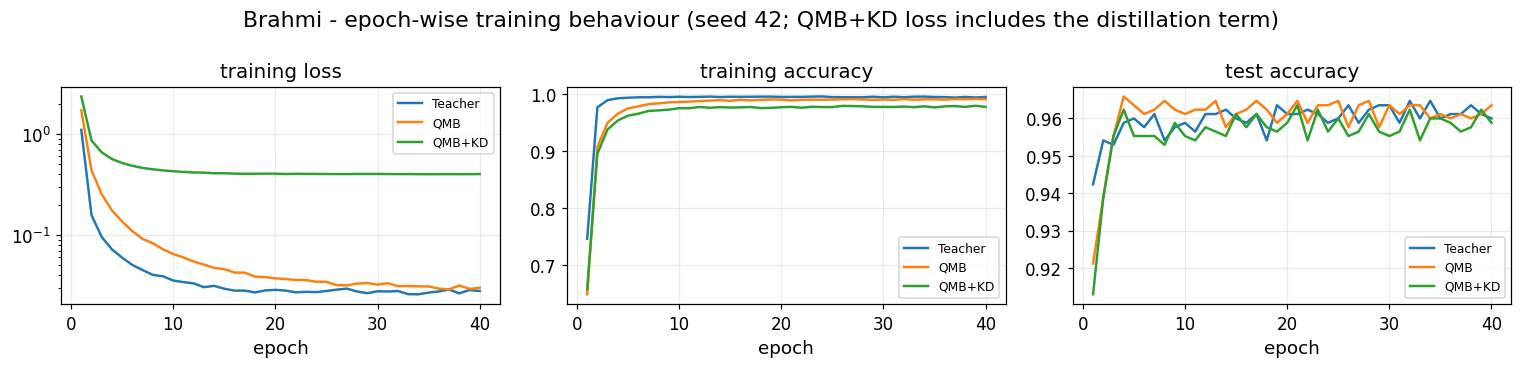

[E2 Modi] seed 42: teacher 0.2757 | QMB 0.2557 | +KD 0.2671 | diff +0.0114
[E2 Modi] seed 43: teacher 0.2929 | QMB 0.2571 | +KD 0.2643 | diff +0.0071
[E2 Modi] seed 44: teacher 0.2686 | QMB 0.2500 | +KD 0.2657 | diff +0.0157
[E2 Modi] seed 45: teacher 0.2771 | QMB 0.2571 | +KD 0.2700 | diff +0.0129
[E2 Modi] seed 46: teacher 0.2843 | QMB 0.2543 | +KD 0.2829 | diff +0.0286
[E2 Modi] KD−noKD = +0.0151 ± 0.0081 | positive 5/5 | Wilcoxon p = 0.062


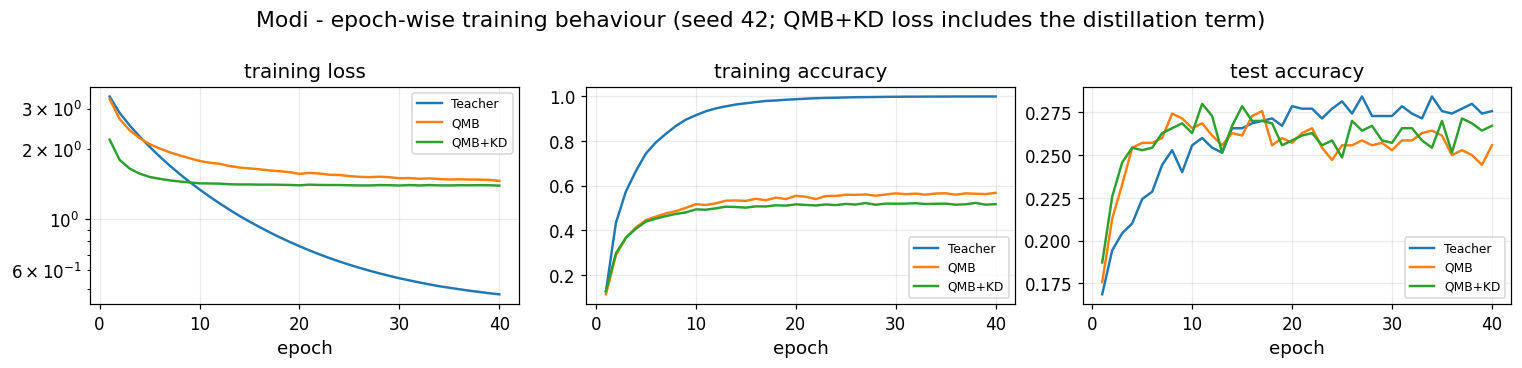

In [7]:
E2 = {}
if RUN_E2_KD_PAIRED:
    for name, d in DATA.items():
        n_classes = len(d["classes"])
        Xa, ya, Xte, yte = d["Xtr_a"], d["ytr_a"], d["Xte"], d["yte"]
        Ftr, Fte = FEATS[name]["Ftr"], FEATS[name]["Fte"]
        accs_q, accs_kd, diffs = [], [], []
        hists = {}
        for s in SEEDS_RUN:
            torch.manual_seed(s)
            teacher = FlyMushroomBodyNet(D_IN, n_classes, seed=s)
            teacher, _, a_t, _ = train_model(teacher, Xa, ya, Xte, yte, n_classes,
                                             f"{name}/E2/teacher/s{s}")
            if s == SEEDS_RUN[0]: hists["Teacher"] = teacher._hist
            torch.manual_seed(s)
            h = MBONHead(qmb.n_features, n_classes)
            hq, p_q, a_q, _ = train_model(h, Ftr, ya, Fte, yte, n_classes,
                                          f"{name}/E2/QMB/s{s}")
            if s == SEEDS_RUN[0]: hists["QMB"] = hq._hist
            torch.manual_seed(s)
            h = MBONHead(qmb.n_features, n_classes)
            hk, p_k, a_k, _ = train_model(h, Ftr, ya, Fte, yte, n_classes,
                                          f"{name}/E2/QMB+KD/s{s}",
                                          teacher=teacher, teacher_inputs=Xa)
            if s == SEEDS_RUN[0]: hists["QMB+KD"] = hk._hist
            accs_q.append(a_q); accs_kd.append(a_k); diffs.append(a_k - a_q)
            print(f"[E2 {name}] seed {s}: teacher {a_t:.4f} | QMB {a_q:.4f} | "
                  f"+KD {a_k:.4f} | diff {a_k-a_q:+.4f}")
        md_, sd_ = msd(diffs)
        pos = sum(x > 0 for x in diffs)
        try:
            from scipy.stats import wilcoxon
            stat, pval = wilcoxon(diffs)
            ptxt = f"Wilcoxon p = {pval:.3f}"
        except Exception:
            ptxt = "scipy unavailable (report sign count)"
        E2[name] = (md_, sd_, pos)
        print(f"[E2 {name}] KD−noKD = {md_:+.4f} ± {sd_:.4f} | positive {pos}/5 | {ptxt}")

        # --- epoch-wise training curves (reference seed) ---
        fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
        for tag_, hcur in hists.items():
            ep = range(1, len(hcur["loss"]) + 1)
            ax[0].plot(ep, hcur["loss"], label=tag_)
            ax[1].plot(ep, hcur["train_acc"], label=tag_)
            ax[2].plot(ep, hcur["test_acc"], label=tag_)
        ax[0].set_title("training loss"); ax[0].set_yscale("log")
        ax[1].set_title("training accuracy")
        ax[2].set_title("test accuracy")
        for a_ in ax: a_.set_xlabel("epoch"); a_.legend(fontsize=8)
        fig.suptitle(f"{name} - epoch-wise training behaviour (seed {SEEDS_RUN[0]}; "
                     f"QMB+KD loss includes the distillation term)")
        plt.tight_layout()
        plt.savefig(f"fig_training_{name}.png", dpi=200); plt.show()

## E3: Measurement budget: repeated realizations + both predictors
Fixed-head condition with `E3_REPEATS` sampling realizations per budget (mean ± std);
retrained condition at the full 40 epochs; diagonal top-two predictor **and** the
covariance-aware Monte-Carlo predictor (Proposition prop:margin), with within-setting
covariances from the shared-sample formula via a fast Walsh--Hadamard transform.

[E3 Brahmi] exact-head reference acc 0.9635
[E3 Brahmi] base logit covariances built: (850, 170, 170)
[E3 Brahmi] M=   512: fixed 0.8928 ± 0.0068 (n=10) | retrained(40ep) 0.8753 | pred-diag 0.9116 | pred-cov 0.8909
[E3 Brahmi] M=  1024: fixed 0.9376 ± 0.0087 (n=10) | retrained(40ep) 0.9224 | pred-diag 0.9368 | pred-cov 0.9353
[E3 Brahmi] M=  4096: fixed 0.9581 ± 0.0017 (n=10) | retrained(40ep) 0.9600 | pred-diag 0.9554 | pred-cov 0.9601
[E3 Brahmi] M= 16384: fixed 0.9635 ± 0.0025 (n=10) | retrained(40ep) 0.9647 | pred-diag 0.9603 | pred-cov 0.9639


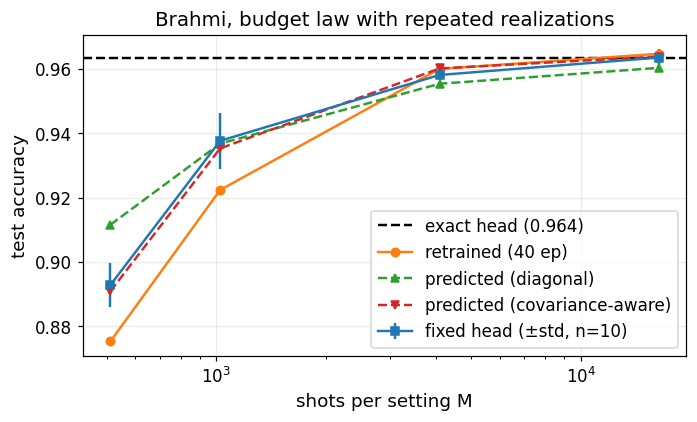

[E3 Modi] exact-head reference acc 0.2557
[E3 Modi] base logit covariances built: (700, 35, 35)
[E3 Modi] M=   512: fixed 0.1321 ± 0.0140 (n=10) | retrained(40ep) 0.1314 | pred-diag 0.1622 | pred-cov 0.1330
[E3 Modi] M=  1024: fixed 0.1741 ± 0.0158 (n=10) | retrained(40ep) 0.1700 | pred-diag 0.1733 | pred-cov 0.1668
[E3 Modi] M=  4096: fixed 0.2161 ± 0.0105 (n=10) | retrained(40ep) 0.2100 | pred-diag 0.1991 | pred-cov 0.2193
[E3 Modi] M= 16384: fixed 0.2437 ± 0.0061 (n=10) | retrained(40ep) 0.2586 | pred-diag 0.2223 | pred-cov 0.2430


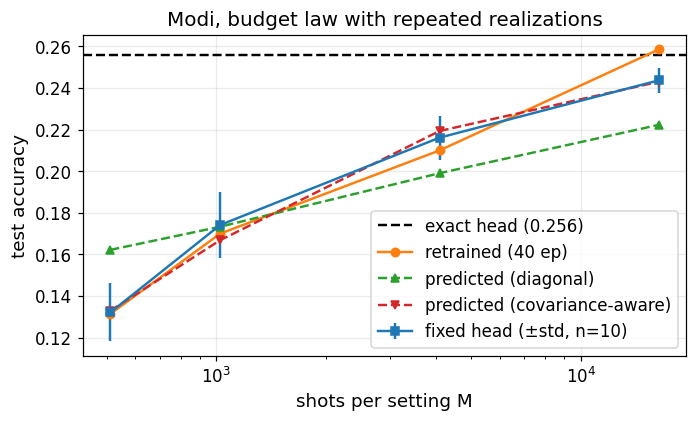

In [8]:
E3 = {}
if RUN_E3_BUDGET:
    Phi = lambda t: 0.5 * (1 + torch.erf(t / math.sqrt(2)))
    for name, d in DATA.items():
        n_classes = len(d["classes"])
        yte = d["yte"]
        Ftr, Fte, mu, sd = (FEATS[name][k] for k in ("Ftr", "Fte", "mu", "sd"))
        torch.manual_seed(SEED)
        head = MBONHead(qmb.n_features, n_classes)
        head, _, a_ex, _ = train_model(head, Ftr, d["ytr_a"], Fte, yte, n_classes,
                                       f"{name}/E3/exact-head")
        head = head.cpu().eval()
        W = head.net[1].weight.detach(); b = head.net[1].bias.detach()
        print(f"[E3 {name}] exact-head reference acc {a_ex:.4f}")

        # --- per-sample base covariance of standardized features (scale 1/M later) ---
        n_sub = len(qmb.subsets)
        masks = qmb.masks
        XOR = masks.unsqueeze(0) ^ masks.unsqueeze(1)          # (n_sub, n_sub)
        Dinv = (1.0 / sd[0]).clone()
        Vb_list = []
        with torch.no_grad():
            logits = Fte @ W.T + b
        for sl, P in qmb.probs(d["Xte"]):
            for i in range(P["Z"].shape[0]):
                blocks = []
                for bi, basis in enumerate(("Z", "X", "Y")):
                    par = fwht(P[basis][i])                     # all parities
                    phiT = par[masks]
                    cov = par[XOR] - phiT.unsqueeze(1) * phiT.unsqueeze(0)
                    blocks.append(cov)
                Sz = torch.zeros(qmb.n_features, qmb.n_features)
                for bi in range(3):
                    s0 = bi * n_sub
                    Sz[s0:s0+n_sub, s0:s0+n_sub] = blocks[bi]
                Sz = Dinv.unsqueeze(1) * Sz * Dinv.unsqueeze(0)
                Vb_list.append(W @ Sz @ W.T)                    # base logit covariance (M=1)
        Vb = torch.stack(Vb_list)
        print(f"[E3 {name}] base logit covariances built: {tuple(Vb.shape)}")

        top2 = logits.topk(2, dim=1)
        c1, c2 = top2.indices[:, 0], top2.indices[:, 1]
        margin = top2.values[:, 0] - top2.values[:, 1]
        correct = (c1 == yte)
        var_raw = (1 - FEATS[name]["Fte_raw"] ** 2).clamp(min=0) / (sd ** 2)
        dW = W[c1] - W[c2]

        res = {}
        for M in E3_BUDGETS:
            fixed = []
            for r in range(E3_REPEATS):
                gen = torch.Generator().manual_seed(1000 + r)
                Ste = qmb.features(d["Xte"], shots=M, gen=gen)
                a_fx, _ = eval_batched(head, (Ste - mu) / sd, yte)
                fixed.append(a_fx)
            mf, sf = msd(fixed)

            gen = torch.Generator().manual_seed(SEED + 3)       # retrained @ full epochs
            Str = qmb.features(d["Xtr_a"], shots=M, gen=gen)
            Ste = qmb.features(d["Xte"], shots=M, gen=gen)
            S1, S2, _, _ = standardize(Str, Ste)
            torch.manual_seed(SEED)
            h2 = MBONHead(qmb.n_features, n_classes)
            _, _, a_re, _ = train_model(h2, S1, d["ytr_a"], S2, yte, n_classes,
                                        f"{name}/E3/M{M}", epochs=EPOCHS)

            s_diag = torch.sqrt((dW ** 2 * var_raw).sum(1) / M) + 1e-12
            p_diag = (Phi(margin / s_diag) * correct.float()).mean().item()

            g = torch.Generator().manual_seed(7)                 # covariance-aware MC
            hits = 0
            for i in range(len(yte)):
                V = Vb[i] / M
                L = torch.linalg.cholesky(V + 1e-9 * torch.eye(n_classes))
                eta = torch.randn(E3_MC_DRAWS, n_classes, generator=g) @ L.T
                pred = (logits[i].unsqueeze(0) + eta).argmax(1)
                hits += (pred == yte[i]).float().mean().item()
            p_cov = hits / len(yte)

            res[M] = (mf, sf, a_re, p_diag, p_cov)
            print(f"[E3 {name}] M={M:>6}: fixed {mf:.4f} ± {sf:.4f} "
                  f"(n={E3_REPEATS}) | retrained(40ep) {a_re:.4f} | "
                  f"pred-diag {p_diag:.4f} | pred-cov {p_cov:.4f}")
        E3[name] = dict(exact=a_ex, budgets=res)

        xs = E3_BUDGETS
        plt.figure(figsize=(6.5, 4))
        plt.axhline(a_ex, ls="--", color="k", label=f"exact head ({a_ex:.3f})")
        plt.errorbar(xs, [res[M][0] for M in xs], yerr=[res[M][1] for M in xs],
                     fmt="s-", label=f"fixed head (±std, n={E3_REPEATS})")
        plt.plot(xs, [res[M][2] for M in xs], "o-", label="retrained (40 ep)")
        plt.plot(xs, [res[M][3] for M in xs], "^--", label="predicted (diagonal)")
        plt.plot(xs, [res[M][4] for M in xs], "v--", label="predicted (covariance-aware)")
        plt.xscale("log"); plt.xlabel("shots per setting M"); plt.ylabel("test accuracy")
        plt.title(f"{name}, budget law with repeated realizations"); plt.legend()
        plt.tight_layout(); plt.savefig(f"fig_budget_{name}.png", dpi=200); plt.show()

## E4: Depth × circuit seeds with validation-based selection + alignment diagnostics
Stratified 10% validation carved from the development data; depth selected on validation
accuracy; test touched once per configuration for reporting. Alignment uses
double-centered Gram matrices ($HKH$).

[E4 Brahmi] train 3910 (+aug 11730) | val 340
[E4 Brahmi] depth 1 seed 7: val 0.9765 | test 0.9612 | CKA(teacher) 0.732 | CKA(labels) 0.428
[E4 Brahmi] depth 1 seed 8: val 0.9676 | test 0.9659 | CKA(teacher) 0.741 | CKA(labels) 0.424
[E4 Brahmi] depth 1 seed 9: val 0.9735 | test 0.9671 | CKA(teacher) 0.723 | CKA(labels) 0.425
[E4 Brahmi] depth 2 seed 7: val 0.9647 | test 0.9588 | CKA(teacher) 0.788 | CKA(labels) 0.470
[E4 Brahmi] depth 2 seed 8: val 0.9706 | test 0.9576 | CKA(teacher) 0.778 | CKA(labels) 0.430
[E4 Brahmi] depth 2 seed 9: val 0.9588 | test 0.9588 | CKA(teacher) 0.784 | CKA(labels) 0.449
[E4 Brahmi] depth 3 seed 7: val 0.9765 | test 0.9612 | CKA(teacher) 0.813 | CKA(labels) 0.473
[E4 Brahmi] depth 3 seed 8: val 0.9706 | test 0.9529 | CKA(teacher) 0.796 | CKA(labels) 0.470
[E4 Brahmi] depth 3 seed 9: val 0.9706 | test 0.9624 | CKA(teacher) 0.806 | CKA(labels) 0.485
[E4 Brahmi] depth 4 seed 7: val 0.9618 | test 0.9624 | CKA(teacher) 0.850 | CKA(labels) 0.514
[E4 Brahmi] de

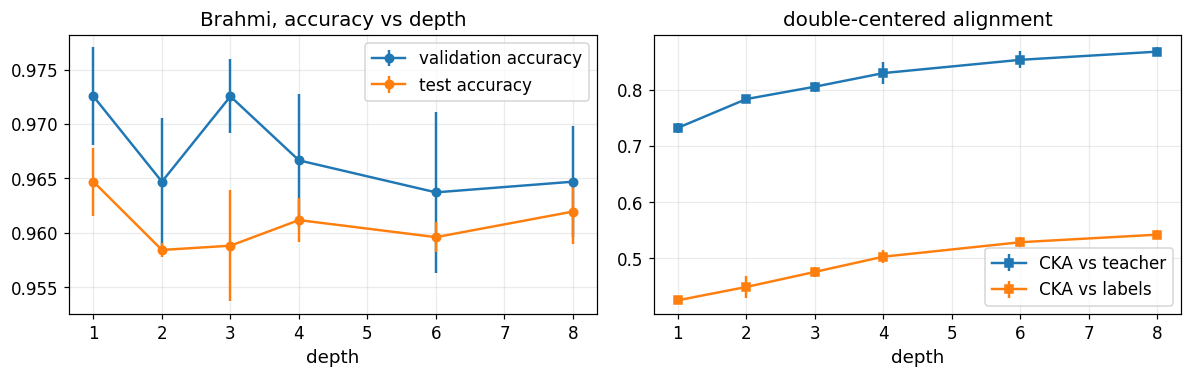

[E4 Modi] train 2520 (+aug 7560) | val 280
[E4 Modi] depth 1 seed 7: val 0.4071 | test 0.3343 | CKA(teacher) 0.582 | CKA(labels) 0.157
[E4 Modi] depth 1 seed 8: val 0.3250 | test 0.3257 | CKA(teacher) 0.581 | CKA(labels) 0.142
[E4 Modi] depth 1 seed 9: val 0.3357 | test 0.3086 | CKA(teacher) 0.565 | CKA(labels) 0.146
[E4 Modi] depth 2 seed 7: val 0.3286 | test 0.3000 | CKA(teacher) 0.603 | CKA(labels) 0.157
[E4 Modi] depth 2 seed 8: val 0.3036 | test 0.2657 | CKA(teacher) 0.596 | CKA(labels) 0.148
[E4 Modi] depth 2 seed 9: val 0.2821 | test 0.2714 | CKA(teacher) 0.589 | CKA(labels) 0.154
[E4 Modi] depth 3 seed 7: val 0.2107 | test 0.2529 | CKA(teacher) 0.627 | CKA(labels) 0.164
[E4 Modi] depth 3 seed 8: val 0.2179 | test 0.2514 | CKA(teacher) 0.605 | CKA(labels) 0.153
[E4 Modi] depth 3 seed 9: val 0.2750 | test 0.2700 | CKA(teacher) 0.614 | CKA(labels) 0.157
[E4 Modi] depth 4 seed 7: val 0.2500 | test 0.2514 | CKA(teacher) 0.651 | CKA(labels) 0.172
[E4 Modi] depth 4 seed 8: val 0.2607 

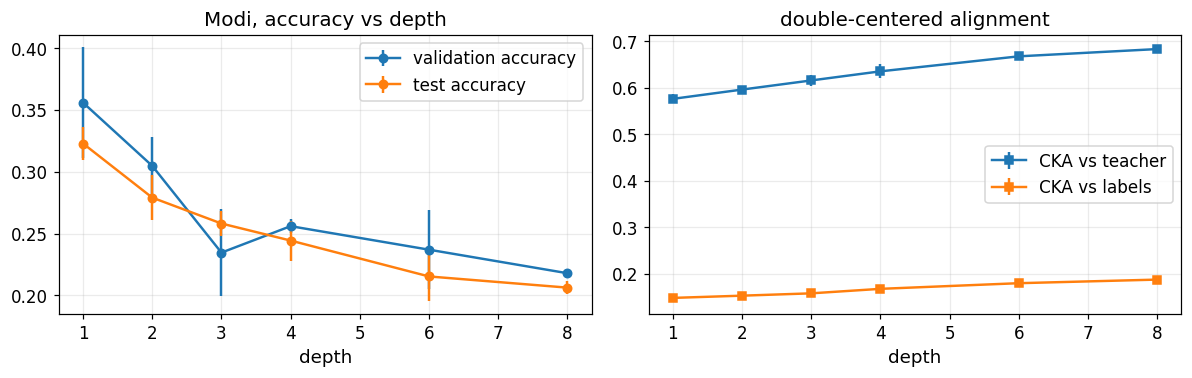

In [9]:
E4 = {}
if RUN_E4_DEPTH:
    def centered_alignment(K, G):
        q = K.shape[0]
        H = torch.eye(q) - torch.ones(q, q) / q
        Kc, Gc = H @ K @ H, H @ G @ H
        return ((Kc * Gc).sum() / (Kc.norm() * Gc.norm() + 1e-12)).item()

    for name, d in DATA.items():
        n_classes = len(d["classes"])
        tr_i, va_i = stratified_indices(d["ytr"], n_classes, VAL_FRAC, SEED + 10)
        Xtr_r, ytr_r = d["Xtr"][tr_i], d["ytr"][tr_i]
        Xva, yva = d["Xtr"][va_i], d["ytr"][va_i]
        Xa, ya = augmented(Xtr_r, ytr_r)
        print(f"[E4 {name}] train {len(ytr_r)} (+aug {len(ya)}) | val {len(yva)}")

        n_probe = min(PROBE_SIZE, len(ytr_r))
        pi = torch.randperm(len(ytr_r), generator=torch.Generator().manual_seed(5))[:n_probe]
        Xp, yp = Xtr_r[pi], ytr_r[pi]
        torch.manual_seed(SEED)
        teacher = FlyMushroomBodyNet(D_IN, n_classes, seed=SEED)
        teacher, _, _, _ = train_model(teacher, Xa, ya, Xva, yva, n_classes,
                                       f"{name}/E4/teacher")
        with torch.no_grad():
            phi_c = teacher.kc_code(Xp)
        K_mb = phi_c @ phi_c.T
        Y1 = F.one_hot(yp, n_classes).float()
        K_lab = Y1 @ Y1.T

        rows = []
        for depth in E4_DEPTHS:
            for cs in E4_CIRCUIT_SEEDS:
                q = QuantumMushroomBody(depth=depth, seed=cs)
                Ftr0, Fva0 = q.features(Xa), q.features(Xva)
                Fte0 = q.features(d["Xte"])
                F1_, F2_, mu_, sd_ = standardize(Ftr0, Fva0)
                F3_ = (Fte0 - mu_) / sd_
                torch.manual_seed(SEED)
                h = MBONHead(q.n_features, n_classes)
                h, _, a_va, _ = train_model(h, F1_, ya, F2_, yva, n_classes,
                                            f"{name}/E4/d{depth}/c{cs}")
                a_te, _ = eval_batched(h, F3_, d["yte"])
                Fp = q.features(Xp)
                Fp = (Fp - Fp.mean(0)) / (Fp.std(0) + 1e-8)
                Kq = Fp @ Fp.T
                al_mb = centered_alignment(Kq, K_mb)
                al_lb = centered_alignment(Kq, K_lab)
                rows.append((depth, cs, a_va, a_te, al_mb, al_lb))
                print(f"[E4 {name}] depth {depth} seed {cs}: val {a_va:.4f} | "
                      f"test {a_te:.4f} | CKA(teacher) {al_mb:.3f} | CKA(labels) {al_lb:.3f}")
        E4[name] = rows
        by_depth = {dep: [r for r in rows if r[0] == dep] for dep in E4_DEPTHS}
        va_means = {dep: np.mean([r[2] for r in v]) for dep, v in by_depth.items()}
        best = max(va_means, key=va_means.get)
        te_at_best = np.mean([r[3] for r in by_depth[best]])
        print(f"[E4 {name}] validation-selected depth = {best} "
              f"(val {va_means[best]:.4f}, test {te_at_best:.4f})")

        fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
        for j, (lab, col) in enumerate([("validation accuracy", 2), ("test accuracy", 3)]):
            m = [np.mean([r[col] for r in by_depth[dep]]) for dep in E4_DEPTHS]
            s = [np.std([r[col] for r in by_depth[dep]], ddof=1) for dep in E4_DEPTHS]
            ax[0].errorbar(E4_DEPTHS, m, yerr=s, fmt="o-", label=lab)
        ax[0].set_xlabel("depth"); ax[0].set_title(f"{name}, accuracy vs depth"); ax[0].legend()
        for lab, col in [("CKA vs teacher", 4), ("CKA vs labels", 5)]:
            m = [np.mean([r[col] for r in by_depth[dep]]) for dep in E4_DEPTHS]
            s = [np.std([r[col] for r in by_depth[dep]], ddof=1) for dep in E4_DEPTHS]
            ax[1].errorbar(E4_DEPTHS, m, yerr=s, fmt="s-", label=lab)
        ax[1].set_xlabel("depth"); ax[1].set_title("double-centered alignment"); ax[1].legend()
        plt.tight_layout(); plt.savefig(f"fig_depth_{name}.png", dpi=200); plt.show()

## E5: Error analysis: normalized confusions, misclassified glyphs, resolution ablation

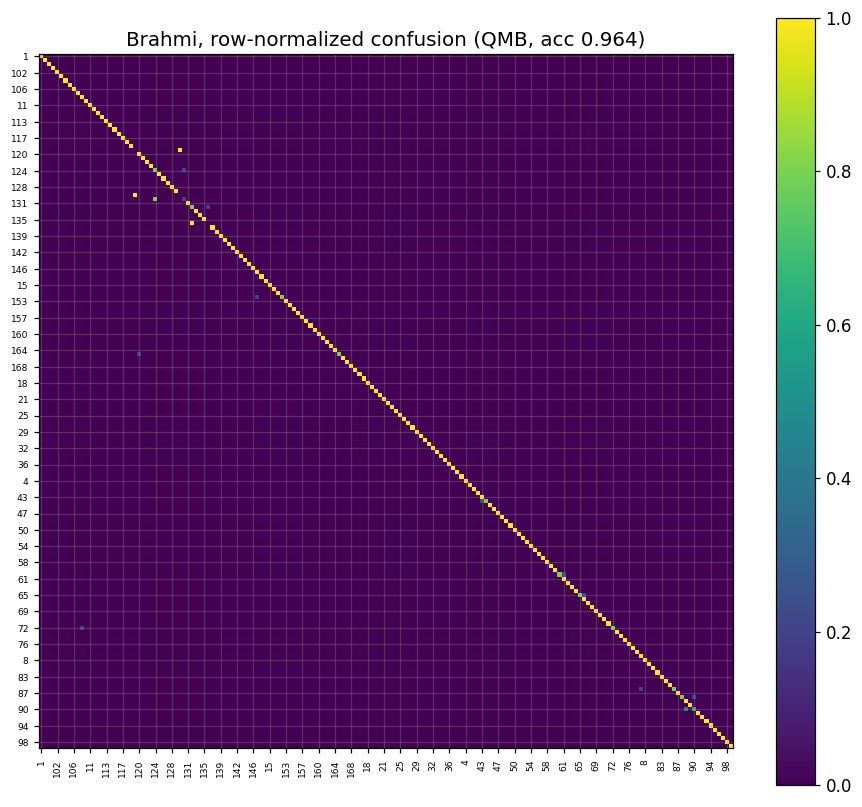

[E5 Brahmi] top directional confusions:
  136 -> 132: 5
  13 -> 12: 5
  12 -> 13: 5
  130 -> 124: 4
  90 -> 89: 2
  88 -> 90: 1
  86 -> 79: 1
  72 -> 108: 1
  65 -> 66: 1
  60 -> 61: 1


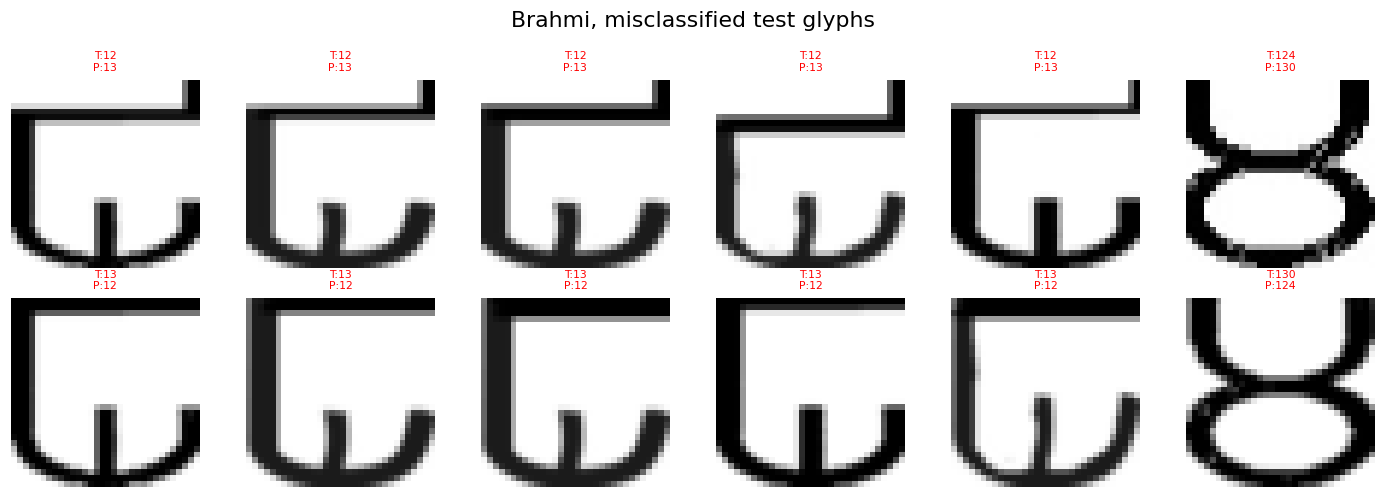

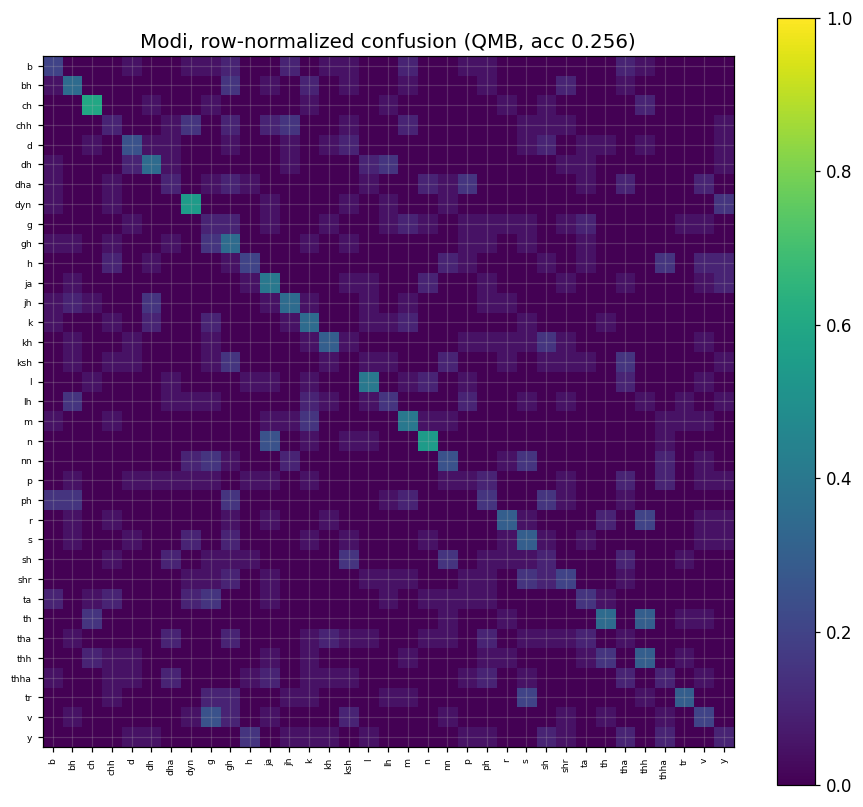

[E5 Modi] top directional confusions:
  th -> thh: 6
  v -> g: 5
  n -> ja: 5
  tr -> s: 4
  r -> thh: 4
  y -> h: 3
  thh -> th: 3
  th -> ch: 3
  ta -> g: 3
  shr -> s: 3


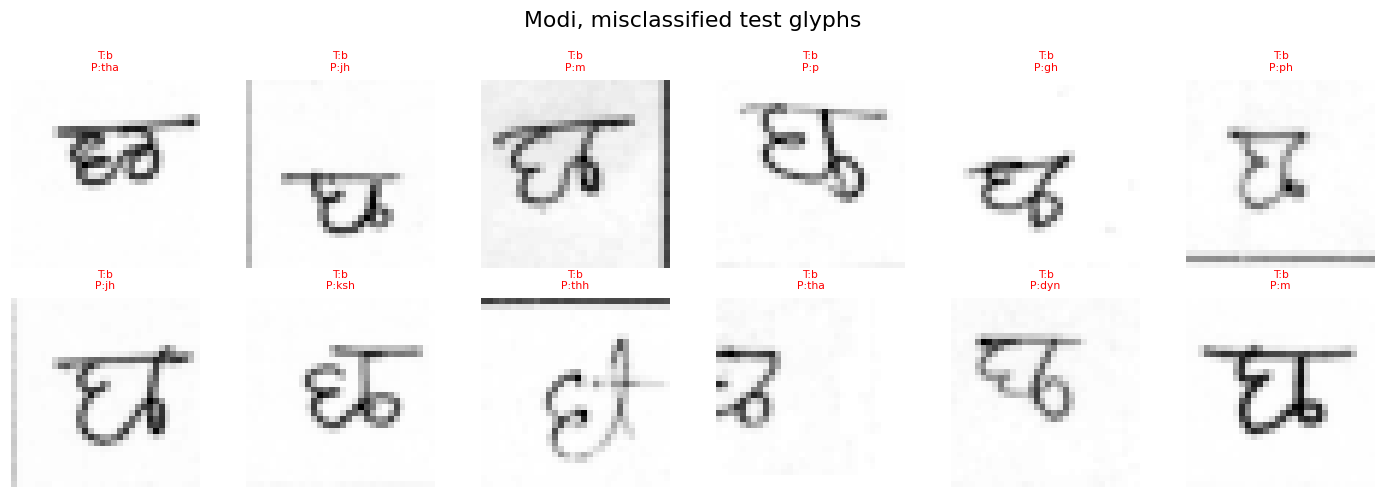

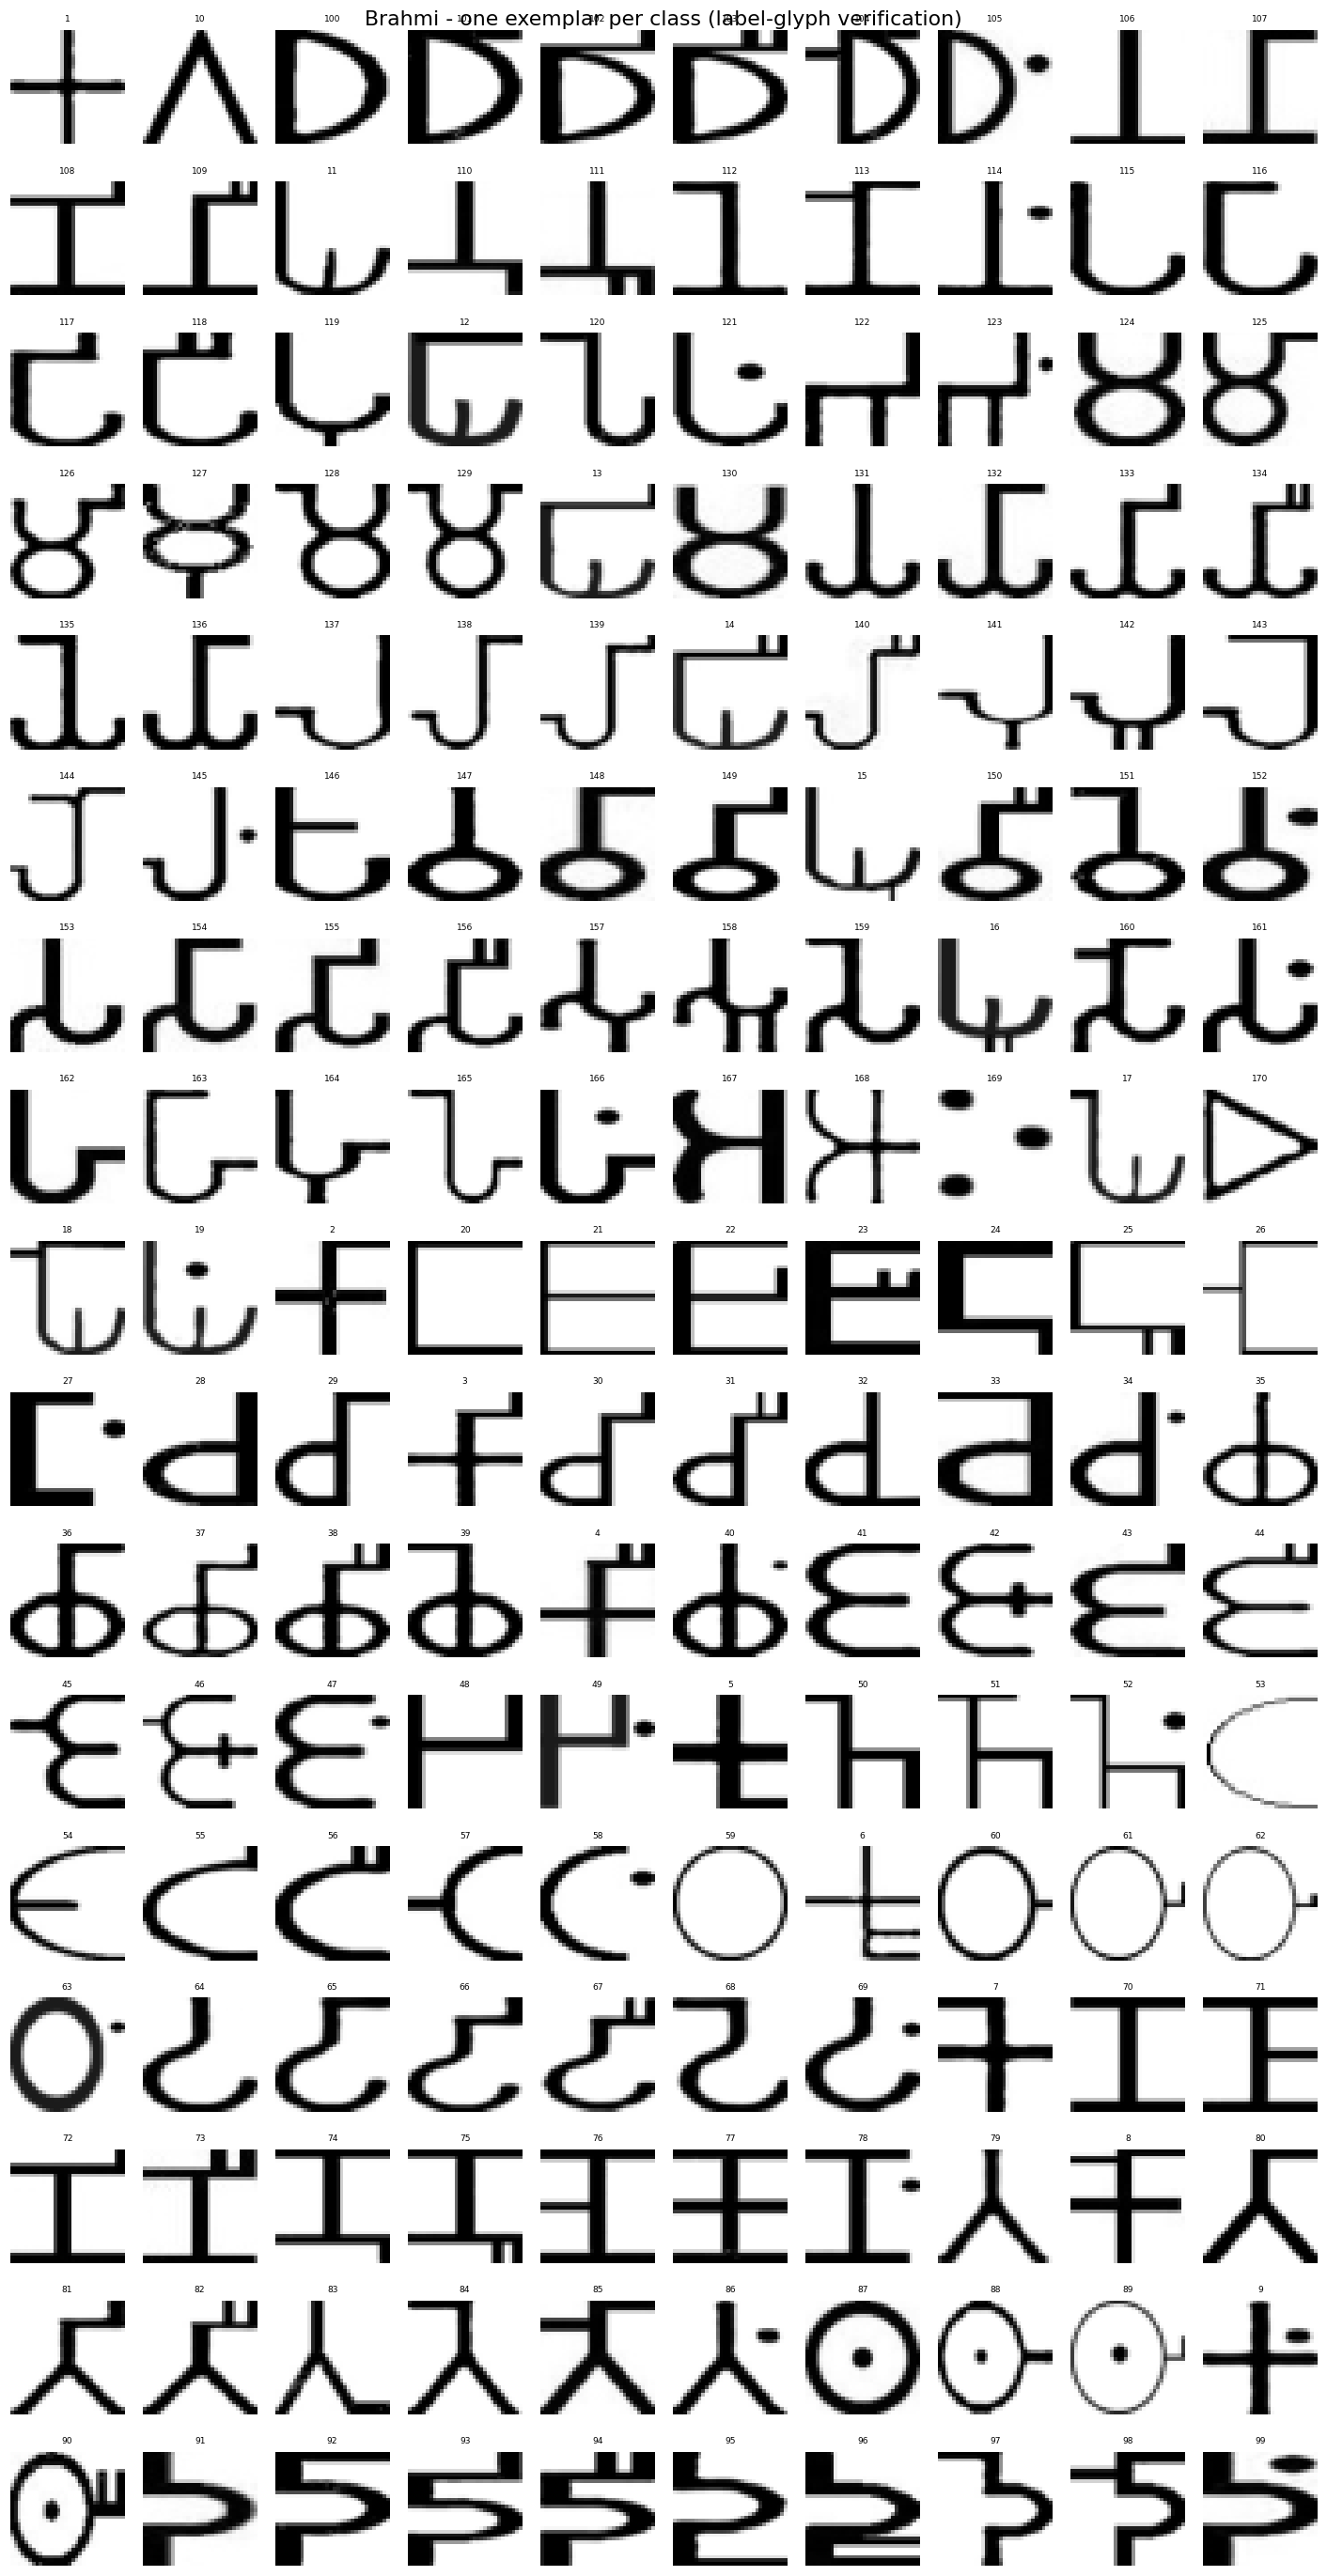

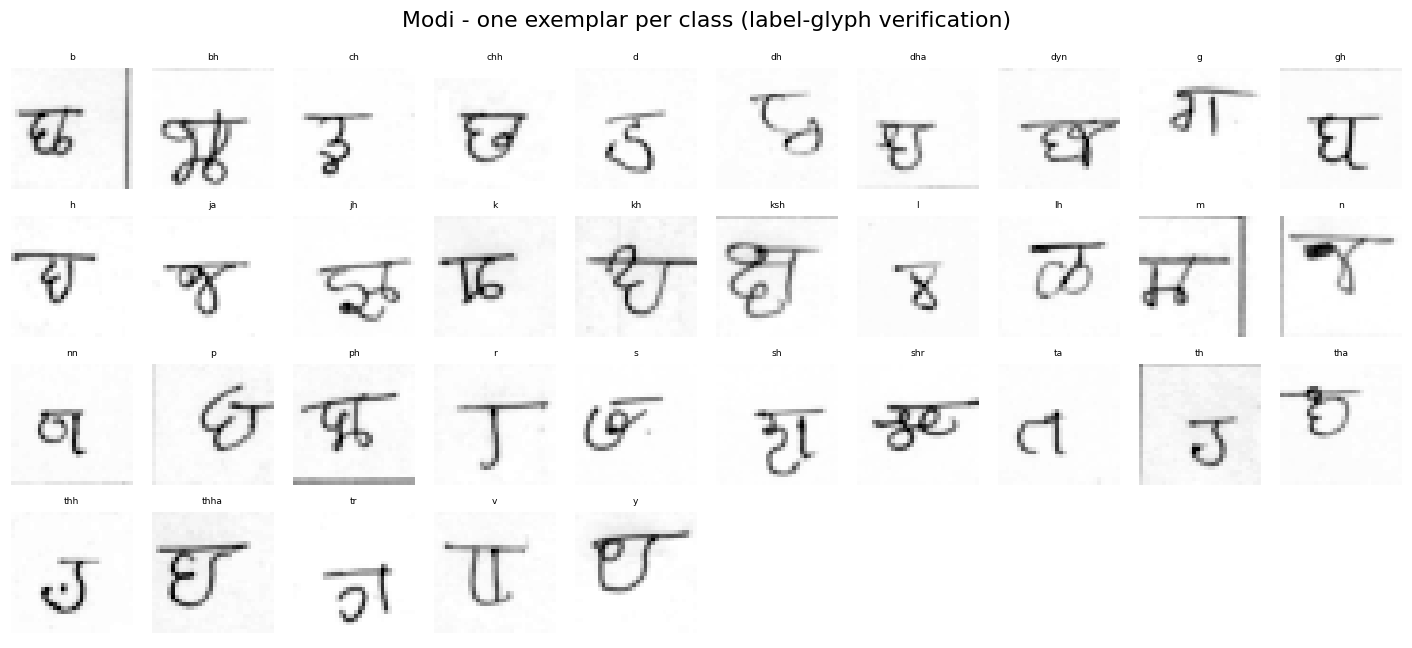

[Modi@32px] 35 classes | train 2800 | test 700 | stratified 80/20 split
[E5 resolution] Modi teacher @ 32px: 0.2790 ± 0.0125 (3 seeds)
[Modi@64px] 35 classes | train 2800 | test 700 | stratified 80/20 split
[E5 resolution] Modi teacher @ 64px: 0.2195 ± 0.0107 (3 seeds)
[E5 resolution] 64px − 32px = -0.0595 -> does NOT support the resolution hypothesis


In [10]:
if RUN_E5_ERRORS:
    for name, d in DATA.items():
        n_classes = len(d["classes"])
        torch.manual_seed(SEED)
        h = MBONHead(qmb.n_features, n_classes)
        h, preds, acc, _ = train_model(h, FEATS[name]["Ftr"], d["ytr_a"],
                                       FEATS[name]["Fte"], d["yte"], n_classes,
                                       f"{name}/E5/ref-head")
        cm = torch.zeros(n_classes, n_classes)
        for t, p in zip(d["yte"], preds): cm[t, p] += 1
        cmn = cm / cm.sum(1, keepdim=True).clamp(min=1)
        plt.figure(figsize=(8.5, 7.5)); plt.imshow(cmn, cmap="viridis", vmin=0, vmax=1)
        step = max(1, n_classes // 40)
        plt.xticks(range(0, n_classes, step),
                   [d["classes"][i] for i in range(0, n_classes, step)],
                   rotation=90, fontsize=6)
        plt.yticks(range(0, n_classes, step),
                   [d["classes"][i] for i in range(0, n_classes, step)], fontsize=6)
        plt.title(f"{name}, row-normalized confusion (QMB, acc {acc:.3f})")
        plt.colorbar(); plt.tight_layout()
        plt.savefig(f"fig_confnorm_{name}.png", dpi=200); plt.show()

        pairs = [(int(cm[i, j].item()), d["classes"][i], d["classes"][j])
                 for i in range(n_classes) for j in range(n_classes) if i != j]
        print(f"[E5 {name}] top directional confusions:")
        for cnt_, a_, b_ in sorted(pairs, reverse=True)[:10]:
            if cnt_ > 0: print(f"  {a_} -> {b_}: {cnt_}")
        wrong = (preds != d["yte"]).nonzero(as_tuple=True)[0][:12]
        if len(wrong):
            fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
            for ax, i in zip(axes.flat, wrong):
                ax.imshow(d["Xte"][i, 0], cmap="gray"); ax.axis("off")
                ax.set_title(f"T:{d['classes'][d['yte'][i]]}\nP:{d['classes'][preds[i]]}",
                             fontsize=7, color="red")
            fig.suptitle(f"{name}, misclassified test glyphs")
            plt.tight_layout(); plt.savefig(f"fig_errors_{name}.png", dpi=200); plt.show()

    # --- label-glyph verification sheet: one exemplar per class ---
    for name, d in DATA.items():
        n_classes = len(d["classes"])
        cols = 10; rows_n = math.ceil(n_classes / cols)
        fig, axes = plt.subplots(rows_n, cols, figsize=(1.3 * cols, 1.5 * rows_n))
        for ax in np.ravel(axes): ax.axis("off")
        for c in range(n_classes):
            i = (d["ytr"] == c).nonzero(as_tuple=True)[0][0]
            ax = np.ravel(axes)[c]
            ax.imshow(d["Xtr"][i, 0], cmap="gray")
            ax.set_title(d["classes"][c], fontsize=6)
        fig.suptitle(f"{name} - one exemplar per class (label-glyph verification)")
        plt.tight_layout()
        plt.savefig(f"fig_classsheet_{name}.png", dpi=200); plt.show()

    # --- resolution ablation (classical teacher; Modi; KC count held fixed) ---
    cfg = DATASETS["Modi"]
    res_rows = {}
    for px in (IMG_SIZE, E5_RES_HI):
        dd = build_dataset("Modi", Path(cfg["folder"]), cfg.get("prefer"),
                           max_per_class=cfg.get("max_per_class"), img_size=px)
        Xa, ya = augmented(dd["Xtr"], dd["ytr"])
        accs = []
        for s in SEEDS_RUN[:3]:
            torch.manual_seed(s)
            t = FlyMushroomBodyNet(px * px, len(dd["classes"]), n_kc=N_KC, seed=s)
            _, _, a, _ = train_model(t, Xa, ya, dd["Xte"], dd["yte"],
                                     len(dd["classes"]), f"Modi@{px}/s{s}")
            accs.append(a)
        m, sdv = msd(accs); res_rows[px] = (m, sdv)
        print(f"[E5 resolution] Modi teacher @ {px}px: {m:.4f} ± {sdv:.4f} (3 seeds)")
    gain = res_rows[E5_RES_HI][0] - res_rows[IMG_SIZE][0]
    print(f"[E5 resolution] {E5_RES_HI}px − {IMG_SIZE}px = {gain:+.4f} "
          f"-> {'supports' if gain > 0.03 else 'does NOT support'} the resolution hypothesis")

## S1: multi-run campaign replication (Supplementary Table S1)

Seven rows of Table S1 under the original protocol: head seeds 42-46,
QMB circuit fixed at seed 7 per depth, RandQuad-525 fixed across runs,
the teacher's sparse projection resampled per seed, and a single-run
FlyMB-525 reference. Printed as mean and population standard deviation
(ddof=0), the convention used in Supplementary Table S1.

In [11]:
RUN_S1_MULTIRUN = True
S1R = {}
if RUN_S1_MULTIRUN:
    def psd(v):
        a = np.asarray(v, float)
        return float(a.mean()), float(a.std(ddof=0))
    rq = RandomQuadraticFeatures(D_IN)
    for name, d in DATA.items():
        ncls = len(d["classes"])
        Xa, ya, Xte, yte = d["Xtr_a"], d["ytr_a"], d["Xte"], d["yte"]
        Z4tr, Z4te = FEATS[name]["Ftr"], FEATS[name]["Fte"]
        qmb8 = QuantumMushroomBody(depth=8)
        Z8tr, Z8te, _, _ = standardize(qmb8.features(Xa), qmb8.features(Xte))
        Rtr, Rte, _, _ = standardize(rq.features(Xa), rq.features(Xte))
        rows = {k: ([], []) for k in
                ("Teacher (10,240)", "RandQuad-525", "QMB (L=4)",
                 "QMB+KD (L=4)", "QMB (L=8)", "QMB+KD (L=8)")}
        for s in SEEDS_RUN:
            torch.manual_seed(s)
            tch = FlyMushroomBodyNet(D_IN, ncls, n_kc=N_KC, seed=s)
            _, _, aT, fT = train_model(tch, Xa, ya, Xte, yte, ncls,
                                       f"S1 {name}/teacher/s{s}")
            rows["Teacher (10,240)"][0].append(aT)
            rows["Teacher (10,240)"][1].append(fT)
            tch = tch.eval()
            plain = (("RandQuad-525", Rtr, Rte), ("QMB (L=4)", Z4tr, Z4te),
                     ("QMB (L=8)", Z8tr, Z8te))
            for lab, Ztr, Zte in plain:
                torch.manual_seed(s)
                h = MBONHead(N_FEAT, ncls)
                _, _, a, f1 = train_model(h, Ztr, ya, Zte, yte, ncls,
                                          f"S1 {name}/{lab}/s{s}")
                rows[lab][0].append(a); rows[lab][1].append(f1)
            for lab, Ztr, Zte in (("QMB+KD (L=4)", Z4tr, Z4te),
                                  ("QMB+KD (L=8)", Z8tr, Z8te)):
                torch.manual_seed(s)
                h = MBONHead(N_FEAT, ncls)
                _, _, a, f1 = train_model(h, Ztr, ya, Zte, yte, ncls,
                                          f"S1 {name}/{lab}/s{s}",
                                          teacher=tch, teacher_inputs=Xa)
                rows[lab][0].append(a); rows[lab][1].append(f1)
        torch.manual_seed(42)        # single-run FlyMB-525 reference
        fm = FlyMushroomBodyNet(D_IN, ncls, n_kc=N_FEAT, seed=42)
        _, _, aF, fF = train_model(fm, Xa, ya, Xte, yte, ncls,
                                   f"S1 {name}/flymb525")
        S1R[name] = {"FlyMB-525 (single run)": ((aF, 0.0), (fF, 0.0))}
        print(f"\n[S1 {name}] multi-run replication "
              "(mean +/- population sd, ddof=0):")
        print(f"    {'FlyMB-525 (single run)':24s} acc {aF:.4f} | F1 {fF:.4f}")
        for lab, (accs, f1s) in rows.items():
            (ma, sa), (mf, sf) = psd(accs), psd(f1s)
            S1R[name][lab] = ((ma, sa), (mf, sf))
            print(f"    {lab:24s} acc {ma:.4f} +/- {sa:.4f} "
                  f"| F1 {mf:.4f} +/- {sf:.4f}")
        del qmb8, Z8tr, Z8te, Rtr, Rte


[S1 Brahmi] multi-run replication (mean +/- population sd, ddof=0):
    FlyMB-525 (single run)   acc 0.9235 | F1 0.9217
    Teacher (10,240)         acc 0.9579 +/- 0.0030 | F1 0.9551 +/- 0.0036
    RandQuad-525             acc 0.9600 +/- 0.0033 | F1 0.9576 +/- 0.0045
    QMB (L=4)                acc 0.9616 +/- 0.0016 | F1 0.9592 +/- 0.0016
    QMB+KD (L=4)             acc 0.9605 +/- 0.0028 | F1 0.9575 +/- 0.0028
    QMB (L=8)                acc 0.9595 +/- 0.0032 | F1 0.9574 +/- 0.0044
    QMB+KD (L=8)             acc 0.9586 +/- 0.0027 | F1 0.9558 +/- 0.0035

[S1 Modi] multi-run replication (mean +/- population sd, ddof=0):
    FlyMB-525 (single run)   acc 0.1186 | F1 0.1015
    Teacher (10,240)         acc 0.2797 +/- 0.0083 | F1 0.2754 +/- 0.0096
    RandQuad-525             acc 0.1797 +/- 0.0040 | F1 0.1777 +/- 0.0046
    QMB (L=4)                acc 0.2549 +/- 0.0026 | F1 0.2534 +/- 0.0033
    QMB+KD (L=4)             acc 0.2700 +/- 0.0067 | F1 0.2653 +/- 0.0070
    QMB (L=8)       

## S3: extended-controls replication (Supplementary Table S3)

The five families at the shared feature budget under the identical
pipeline (three head seeds), with the 530-image overlap-filtered Brahmi
subset evaluated for the four re-evaluated models. Identity here is the
unmasked implementation, as in Supplementary Table S3; the masked
identity baseline is computed in the main pipeline notebook.

In [13]:
def stratified_pick(y, k, seed=0):
    g = torch.Generator().manual_seed(seed)
    order = torch.randperm(len(y), generator=g)
    chosen, seen = [], {}
    for i in order:
        c = int(y[i])
        if seen.get(c, 0) < max(1, k // len(set(y.tolist()))) \
                or len(chosen) < k:
            if len(chosen) < k:
                chosen.append(int(i)); seen[c] = seen.get(c, 0) + 1
        if len(chosen) == k:
            break
    return torch.tensor(chosen)

In [14]:
RUN_S3_CONTROLS = True
S3R = {}
if RUN_S3_CONTROLS:
    import hashlib

    def random_u2(gen):
        z = torch.randn(2, 2, generator=gen, dtype=torch.float64) \
            + 1j * torch.randn(2, 2, generator=gen, dtype=torch.float64)
        q, r = torch.linalg.qr(z)
        dg = torch.diagonal(r)
        return (q * (dg / dg.abs())).contiguous().to(torch.complex64)

    class FixedUnitaryQMB(QuantumMushroomBody):
        def __init__(self, U):
            super().__init__(depth=0)
            self.U = U

    class NystromPoly2Features:
        """Degree-2 polynomial-kernel control, Nystrom-approximated with
        N_FEAT stratified landmark training images."""
        def __init__(self, X_land, eps=1e-6):
            self.Uland = pn_normalize(X_land)
            Kmm = (self.Uland @ self.Uland.T) ** 2
            lam, V = torch.linalg.eigh(Kmm.double())
            keep = lam > eps * lam.max()
            self.W = (V[:, keep] * lam[keep].rsqrt()).float()
            self.n_features = self.W.shape[1]
        def features(self, X, batch=512):
            out = torch.empty(len(X), self.n_features)
            for i in range(0, len(X), batch):
                Kb = (pn_normalize(X[i:i + batch]) @ self.Uland.T) ** 2
                out[i:i + batch] = Kb @ self.W
            return out

    gen = torch.Generator().manual_seed(QMB_SEED)
    Uprod = torch.eye(1, dtype=torch.complex64)
    for _ in range(N_QUBITS):
        Uprod = torch.kron(Uprod, random_u2(gen))

    def _hash(x):
        return hashlib.md5((x[0] * 255).round().to(torch.uint8)
                           .numpy().tobytes()).hexdigest()

    for name, d in DATA.items():
        ncls = len(d["classes"])
        Xa, ya, Xte, yte = d["Xtr_a"], d["ytr_a"], d["Xte"], d["yte"]
        sub = None
        if name == "Brahmi":   # test images with no byte-identical train copy
            tr_h = {_hash(d["Xtr"][i]) for i in range(len(d["ytr"]))}
            sub = torch.tensor([j for j in range(len(yte))
                                if _hash(d["Xte"][j]) not in tr_h])
            print(f"[S3 {name}] overlap-filtered subset: {len(sub)} images")
        land = stratified_pick(d["ytr"], min(N_FEAT, len(d["ytr"])), seed=SEED)
        fams = {
            "QMB (L=4)": None,                       # reuse FEATS
            "Identity circuit (L=0, unmasked)":
                QuantumMushroomBody(depth=0),
            "Product U(2)": FixedUnitaryQMB(Uprod),
            "RandQuad-525": RandomQuadraticFeatures(D_IN),
            "Nystrom poly-2 (525)": NystromPoly2Features(d["Xtr"][land]),
        }
        S3R[name] = {}
        for lab, fx in fams.items():
            if fx is None:
                Ztr, Zte = FEATS[name]["Ftr"], FEATS[name]["Fte"]
            else:
                Ztr, Zte, _, _ = standardize(fx.features(Xa),
                                             fx.features(Xte))
            nfeat = Ztr.shape[1]
            full, subacc = [], []
            for s in (42, 43, 44):
                torch.manual_seed(s)
                h = MBONHead(nfeat, ncls)
                _, _, a, _ = train_model(h, Ztr, ya, Zte, yte, ncls,
                                         f"S3 {name}/{lab}/s{s}")
                full.append(a)
                if sub is not None and lab != "Nystrom poly-2 (525)":
                    ac, _ = eval_batched(h, Zte[sub], yte[sub])
                    subacc.append(ac)
            ma, sa = msd(full)
            rec = {"full": (ma, sa)}
            line = f"    {lab:34s} full {ma:.4f} +/- {sa:.4f}"
            if subacc:
                ms_, ss_ = msd(subacc)
                rec["subset530"] = (ms_, ss_)
                line += f" | 530-subset {ms_:.4f} +/- {ss_:.4f}"
            S3R[name][lab] = rec
            print(line)
            del Ztr, Zte

[S3 Brahmi] overlap-filtered subset: 530 images
    QMB (L=4)                          full 0.9627 +/- 0.0014 | 530-subset 0.9635 +/- 0.0022
    Identity circuit (L=0, unmasked)   full 0.9518 +/- 0.0042 | 530-subset 0.9465 +/- 0.0066
    Product U(2)                       full 0.9631 +/- 0.0007 | 530-subset 0.9635 +/- 0.0011
    RandQuad-525                       full 0.9616 +/- 0.0041 | 530-subset 0.9604 +/- 0.0050
    Nystrom poly-2 (525)               full 0.9588 +/- 0.0000
    QMB (L=4)                          full 0.2543 +/- 0.0038
    Identity circuit (L=0, unmasked)   full 0.3148 +/- 0.0070
    Product U(2)                       full 0.3843 +/- 0.0038
    RandQuad-525                       full 0.1781 +/- 0.0022
    Nystrom poly-2 (525)               full 0.2881 +/- 0.0059


## S4: single-run budget replication (Supplementary Table S4)

The single-realization finite-shot experiment at $L=4$: a fixed head
trained on exact features (40 epochs), retrained heads at 20 epochs per
budget, and the diagonal-covariance top-two-margin prediction for the
fixed head. One saved sampling realization per budget, as in Supplementary
Table S4.

In [15]:
RUN_S4_BUDGET1 = True
if RUN_S4_BUDGET1:
    Phi = lambda t: 0.5 * (1 + torch.erf(t / math.sqrt(2)))
    for name, d in DATA.items():
        ncls = len(d["classes"])
        yte = d["yte"]
        Ztr, Zte = FEATS[name]["Ftr"], FEATS[name]["Fte"]
        mu, sd = FEATS[name]["mu"], FEATS[name]["sd"]
        Fte_raw = FEATS[name]["Fte_raw"]
        torch.manual_seed(SEED)
        head = MBONHead(qmb.n_features, ncls)
        _, _, a_ex, _ = train_model(head, Ztr, d["ytr_a"], Zte, yte, ncls,
                                    f"S4 {name}/exact-head")
        head = head.cpu().eval()
        W = head.net[1].weight.detach(); b = head.net[1].bias.detach()
        logits = Zte @ W.T + b
        top2 = logits.topk(2, dim=1)
        print(f"\n[S4 {name}] exact reference {a_ex:.4f}")
        for M in E3_BUDGETS:
            genM = torch.Generator().manual_seed(SEED + M)
            Fh = qmb.features(d["Xte"], shots=M, gen=genM)
            a_fix, _ = eval_batched(head, (Fh - mu) / sd, yte)
            genT = torch.Generator().manual_seed(SEED + M + 1)
            Ftr_s = qmb.features(d["Xtr_a"], shots=M, gen=genT)
            Fte_s = qmb.features(d["Xte"], shots=M, gen=genT)
            Z1s, Z2s, _, _ = standardize(Ftr_s, Fte_s)
            torch.manual_seed(SEED)
            h20 = MBONHead(qmb.n_features, ncls)
            _, _, a_re, _ = train_model(h20, Z1s, d["ytr_a"], Z2s, yte,
                                        ncls, f"S4 {name}/retrain/M{M}",
                                        epochs=20)
            # diagonal top-two prediction: variance of the standardized
            # feature j is (1 - phi_j^2) / (M sd_j^2) per setting
            var = (1 - Fte_raw ** 2).clamp(min=0) / (M * sd[0] ** 2)
            i1, i2 = top2.indices[:, 0], top2.indices[:, 1]
            dW = W[i1] - W[i2]
            sig2 = (dW ** 2 * var).sum(1).clamp(min=1e-12)
            margin = top2.values[:, 0] - top2.values[:, 1]
            # the margin probability counts only images the exact-feature
            # head classifies correctly
            pred = float((Phi(margin / sig2.sqrt())[
                logits.argmax(1) == yte]).sum() / len(yte))
            print(f"    M={M:<6d} fixed {a_fix:.4f} | retrained(20ep) "
                  f"{a_re:.4f} | predicted(diag top-two) {pred:.4f}")
            del Fh, Ftr_s, Fte_s, Z1s, Z2s


[S4 Brahmi] exact reference 0.9635
    M=512    fixed 0.8824 | retrained(20ep) 0.9000 | predicted(diag top-two) 0.9116
    M=1024   fixed 0.9294 | retrained(20ep) 0.9318 | predicted(diag top-two) 0.9368
    M=4096   fixed 0.9518 | retrained(20ep) 0.9576 | predicted(diag top-two) 0.9554
    M=16384  fixed 0.9659 | retrained(20ep) 0.9588 | predicted(diag top-two) 0.9603

[S4 Modi] exact reference 0.2557
    M=512    fixed 0.1514 | retrained(20ep) 0.1557 | predicted(diag top-two) 0.1622
    M=1024   fixed 0.1971 | retrained(20ep) 0.1843 | predicted(diag top-two) 0.1733
    M=4096   fixed 0.2171 | retrained(20ep) 0.2243 | predicted(diag top-two) 0.1991
    M=16384  fixed 0.2443 | retrained(20ep) 0.2500 | predicted(diag top-two) 0.2223


## Q: QPU experiment (Brahmi only)
Tier A: the reference $n{=}10$ protocol on `QPU_A_IMAGES` test glyphs, feature error,
prediction agreement, transpiled resource counts. Tier B: reduced $n{=}8$ register
($16\times16$) on `QPU_B_IMAGES` glyphs, hardware classification accuracy vs the ideal
finite-shot reference. `aer` mode runs the identical path on a local noiseless simulator.

In [16]:
try:
    import numpy as _np
    from qiskit import QuantumCircuit
    from qiskit.circuit.library import UnitaryGate
    IS_QISKIT = True
except ImportError:
    IS_QISKIT = False
    print("qiskit not installed; circuit display and QPU sections are skipped.")

if IS_QISKIT:

    def qmb_circuits_for(qobj, x_image):
        n = qobj.n
        psi = pn_normalize(x_image.unsqueeze(0))[0].numpy().astype(_np.complex128)
        psi = psi / _np.linalg.norm(psi)
        circs = {}
        for basis in ("Z", "X", "Y"):
            qc = QuantumCircuit(n)
            qc.initialize(psi)
            for (q0, q1), Mg in qobj.gates:
                M64 = Mg.numpy().astype(_np.complex128)
                u, _, vh = _np.linalg.svd(M64)
                qc.append(UnitaryGate(u @ vh), [n - 1 - q1, n - 1 - q0])
            for q in range(n):
                if basis == "X": qc.h(q)
                elif basis == "Y": qc.sdg(q); qc.h(q)
            qc.measure_all()
            circs[basis] = qc
        return circs

    def counts_to_features(qobj, counts_by_basis):
        fs = []
        for basis in ("Z", "X", "Y"):
            p = torch.zeros(2 ** qobj.n)
            tot = sum(counts_by_basis[basis].values())
            for bstr, c in counts_by_basis[basis].items():
                p[int(bstr.replace(" ", ""), 2)] = c / tot
            fs.append(qobj.C @ p)
        return torch.cat(fs)

    def twoq_count(qc):
        return sum(1 for inst in qc.data if inst.operation.num_qubits == 2)

    def stratified_pick(y, k, seed=0):
        g = torch.Generator().manual_seed(seed)
        order = torch.randperm(len(y), generator=g)
        chosen, seen = [], {}
        for i in order:
            c = int(y[i])
            if seen.get(c, 0) < max(1, k // len(set(y.tolist()))) or len(chosen) < k:
                if len(chosen) < k:
                    chosen.append(int(i)); seen[c] = seen.get(c, 0) + 1
            if len(chosen) == k: break
        return torch.tensor(chosen)

    def run_counts(circs_flat, shots, tag):
        """Execute circuits; returns (counts_list, transpiled_metrics) in 'aer' mode,
        or saves a submission record in 'ibm-submit' mode."""
        if QPU_MODE == "aer":
            from qiskit_aer import AerSimulator
            backend = AerSimulator()
            job = backend.run(circs_flat, shots=shots)
            counts = job.result().get_counts()
            if isinstance(counts, dict): counts = [counts]
            return counts, {"backend": "AerSimulator (local, noiseless)",
                            "transpiled": False}
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
        from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
        service = QiskitRuntimeService()
        backend = service.least_busy(operational=True, simulator=False,
                                     min_num_qubits=max(c.num_qubits for c in circs_flat))
        pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
        isa = [pm.run(qc) for qc in circs_flat]
        depths = [qc.depth() for qc in isa]
        twoqs = [twoq_count(qc) for qc in isa]
        sampler = SamplerV2(mode=backend)
        sampler.options.dynamical_decoupling.enable = True
        sampler.options.twirling.enable_measure = True
        job = sampler.run(isa, shots=shots)
        rec = {"tag": tag, "job_id": job.job_id(), "backend": backend.name,
               "shots": shots, "n_circuits": len(isa),
               "mitigation": "dynamical decoupling + measurement twirling "
                             "(report as the standard condition)",
               "transpiled_depth_mean": float(_np.mean(depths)),
               "transpiled_depth_max": int(max(depths)),
               "transpiled_2q_mean": float(_np.mean(twoqs)),
               "transpiled_2q_max": int(max(twoqs))}
        store = {}
        if os.path.exists(QPU_JOBS_FILE):
            store = _json.load(open(QPU_JOBS_FILE))
        store[tag] = rec
        _json.dump(store, open(QPU_JOBS_FILE, "w"), indent=1)
        print(f"[QPU submit] {tag}: job {rec['job_id']} on {rec['backend']} | "
              f"2q gates mean {rec['transpiled_2q_mean']:.0f} "
              f"(max {rec['transpiled_2q_max']}), depth max {rec['transpiled_depth_max']}")
        return None, rec

    def retrieve_counts(tag):
        from qiskit_ibm_runtime import QiskitRuntimeService
        rec = _json.load(open(QPU_JOBS_FILE))[tag]
        service = QiskitRuntimeService()
        job = service.job(rec["job_id"])
        result = job.result()
        try:
            rec["execution_date"] = str(getattr(job, "creation_date", None)
                                        or job.metrics().get("timestamps"))
        except Exception:
            rec["execution_date"] = "see IBM dashboard"
        try:
            rec["qpu_usage_seconds"] = job.usage()
        except Exception:
            rec["qpu_usage_seconds"] = "see IBM dashboard"
        print(f"[QPU retrieve] {tag}: backend {rec['backend']} | "
              f"date {rec['execution_date']} | "
              f"QPU usage {rec['qpu_usage_seconds']} | "
              f"mitigation: {rec.get('mitigation', 'none recorded')}")
        counts = []
        for r in result:
            counts.append(r.data.meas.get_counts())
        return counts, rec

### Circuit display
The actual QMB circuit as exported: the amplitude-encoding block, the 18 fixed
$SU(4)$ brickwork blocks ($n{=}10$, $L{=}4$), the basis rotation, and the
computational-basis measurement. The rendered image (`fig_circuit_n10.png`)
is the data-backed basis for the paper's circuit figure.

In [17]:
if IS_QISKIT:
    dB0 = DATA["Brahmi"]
    circs_disp = qmb_circuits_for(qmb, dB0["Xte"][0])
    qcY = circs_disp["Y"]                      # Y branch shows the pre-rotation
    print("ops (Y-basis branch):", dict(qcY.count_ops()))
    print("two-qubit unitary blocks:", sum(1 for inst in qcY.data
                                           if inst.operation.num_qubits == 2))
    try:
        fig = qcY.draw("mpl", fold=24, idle_wires=False)
        fig.suptitle("QMB circuit, Y-measurement branch "
                     "(n=10, L=4; encoding + 18 SU(4) blocks + rotation + measure)",
                     fontsize=9)
        fig.savefig("fig_circuit_n10.png", dpi=200, bbox_inches="tight")
        import matplotlib.pyplot as _plt; _plt.show()
        print("saved fig_circuit_n10.png")
    except Exception as e:
        print(f"matplotlib drawer unavailable ({e}); text rendering instead:")
        print(qcY.draw("text", fold=100))

ops (Y-basis branch): {'unitary': 18, 'sdg': 10, 'h': 10, 'measure': 10, 'initialize': 1, 'barrier': 1}
two-qubit unitary blocks: 18
saved fig_circuit_n10.png


In [20]:
#!pip install -U qiskit-aer

In [21]:
# ---------------- Tier A: n=10 characterization on Brahmi ----------------
if IS_QISKIT and QPU_MODE in ("aer", "ibm-submit", "ibm-retrieve"):
    dB = DATA["Brahmi"]
    idxA = stratified_pick(dB["yte"], QPU_A_IMAGES, seed=11)
    XA, yA = dB["Xte"][idxA], dB["yte"][idxA]
    f_exact_A = qmb.features(XA)

    if QPU_MODE in ("aer", "ibm-submit"):
        flat = []
        for i in range(len(idxA)):
            cs = qmb_circuits_for(qmb, XA[i])
            flat += [cs["Z"], cs["X"], cs["Y"]]
        countsA, recA = run_counts(flat, QPU_SHOTS, "tierA_n10")
    else:
        countsA, recA = retrieve_counts("tierA_n10")

    if countsA is not None:
        n_classes = len(dB["classes"])
        torch.manual_seed(SEED)
        headA = MBONHead(qmb.n_features, n_classes)
        headA, _, _, _ = train_model(headA, FEATS["Brahmi"]["Ftr"], dB["ytr_a"],
                                     FEATS["Brahmi"]["Fte"], dB["yte"], n_classes,
                                     "QPU/tierA-head")
        headA = headA.cpu().eval()
        mu, sd = FEATS["Brahmi"]["mu"], FEATS["Brahmi"]["sd"]
        feats_hw, agree = [], 0
        with torch.no_grad():
            z_ex = (f_exact_A - mu) / sd
            pred_ideal = headA(z_ex).argmax(1)
        for i in range(len(idxA)):
            cb = {b: countsA[3 * i + j] for j, b in enumerate(("Z", "X", "Y"))}
            feats_hw.append(counts_to_features(qmb, cb))
        F_hw = torch.stack(feats_hw)
        mae = (F_hw - f_exact_A).abs().mean().item()
        mx  = (F_hw - f_exact_A).abs().max().item()
        with torch.no_grad():
            pred_hw = headA((F_hw - mu) / sd).argmax(1)
        agree = (pred_hw == pred_ideal).float().mean().item()
        acc_hw = (pred_hw == yA).float().mean().item()
        acc_id = (pred_ideal == yA).float().mean().item()
        shot_floor = 1 / math.sqrt(QPU_SHOTS)
        print(f"[Tier A] backend: {recA['backend']} | images {len(idxA)} | "
              f"shots/setting {QPU_SHOTS}")
        print(f"[Tier A] feature MAE {mae:.4f} (max {mx:.4f}); "
              f"shot-noise floor ~{shot_floor:.4f}")
        print(f"[Tier A] prediction agreement with ideal: {agree:.3f} | "
              f"acc hw {acc_hw:.3f} vs ideal-exact {acc_id:.3f}")

[Tier A] backend: AerSimulator (local, noiseless) | images 10 | shots/setting 1024
[Tier A] feature MAE 0.0250 (max 0.1150); shot-noise floor ~0.0312
[Tier A] prediction agreement with ideal: 1.000 | acc hw 1.000 vs ideal-exact 1.000


In [22]:
# ---------------- Tier B: n=8 (16x16) classification on Brahmi ----------------
if IS_QISKIT and QPU_MODE in ("aer", "ibm-submit", "ibm-retrieve"):
    cfgB = DATASETS["Brahmi"]
    d16 = build_dataset("Brahmi16", Path(cfgB["folder"]), img_size=QPU_B_IMG_SIZE)
    n8 = int(math.log2(QPU_B_IMG_SIZE ** 2))
    qmb8 = QuantumMushroomBody(n_qubits=n8, depth=DEPTH, seed=QMB_SEED)
    print(f"[Tier B] n={n8} qubits, {qmb8.n_features} features")
    Xa16, ya16 = augmented(d16["Xtr"], d16["ytr"])
    F1_, F2_ = qmb8.features(Xa16), qmb8.features(d16["Xte"])
    Z1, Z2, mu8, sd8 = standardize(F1_, F2_)
    n_classes = len(d16["classes"])
    torch.manual_seed(SEED)
    head8 = MBONHead(qmb8.n_features, n_classes)
    head8, _, a8, _ = train_model(head8, Z1, ya16, Z2, d16["yte"], n_classes,
                                  "QPU/tierB-head")
    print(f"[Tier B] exact-feature reference accuracy @16px: {a8:.4f}")

    idxB = stratified_pick(d16["yte"], QPU_B_IMAGES, seed=12)
    XB, yB = d16["Xte"][idxB], d16["yte"][idxB]
    gen = torch.Generator().manual_seed(2024)
    f_ideal_shots = qmb8.features(XB, shots=QPU_SHOTS, gen=gen)
    head8 = head8.cpu().eval()
    with torch.no_grad():
        acc_ideal_shots = (head8((f_ideal_shots - mu8) / sd8).argmax(1) == yB)\
                          .float().mean().item()

    if QPU_MODE in ("aer", "ibm-submit"):
        flat = []
        for i in range(len(idxB)):
            cs = qmb_circuits_for(qmb8, XB[i])
            flat += [cs["Z"], cs["X"], cs["Y"]]
        countsB, recB = run_counts(flat, QPU_SHOTS, "tierB_n8")
    else:
        countsB, recB = retrieve_counts("tierB_n8")

    if countsB is not None:
        feats_hw = []
        for i in range(len(idxB)):
            cb = {b: countsB[3 * i + j] for j, b in enumerate(("Z", "X", "Y"))}
            feats_hw.append(counts_to_features(qmb8, cb))
        F_hw = torch.stack(feats_hw)
        with torch.no_grad():
            pred_hw = head8((F_hw - mu8) / sd8).argmax(1)
        acc_hw = (pred_hw == yB).float().mean().item()
        print(f"[Tier B] backend: {recB['backend']} | images {len(idxB)} | "
              f"shots/setting {QPU_SHOTS}")
        print(f"[Tier B] hardware accuracy {acc_hw:.3f} | "
              f"ideal finite-shot {acc_ideal_shots:.3f} | exact {a8:.4f}")
        print(f"[Tier B] shots total: {3 * QPU_SHOTS * len(idxB):,}")

[Brahmi16@16px] 170 classes | train 4250 | test 850 | existing split (train/test)
[Tier B] n=8 qubits, 276 features
[Tier B] exact-feature reference accuracy @16px: 0.9659
[Tier B] backend: AerSimulator (local, noiseless) | images 50 | shots/setting 1024
[Tier B] hardware accuracy 1.000 | ideal finite-shot 0.980 | exact 0.9659
[Tier B] shots total: 153,600


In [ ]:
# Recorded values of the preliminary campaigns, for comparison against the
# S1, S3, and S4 replication sections above: Supplementary Table S1
# (multi-run), Table S3 (extended controls), Table S4
# (single-run budget). These are the retained outputs of the
# preliminary-campaign notebooks in the release.
S1 = {  # accuracy, macro-F1 (population sd, ddof=0; dagger = single run)
 "Brahmi": {"Teacher (10,240)": ("0.9579+/-0.0030","0.9551+/-0.0036"),
            "FlyMB-525 (single run)": ("0.9224","0.9201"),
            "RandQuad-525": ("0.9600+/-0.0033","0.9576+/-0.0045"),
            "QMB (L=4)": ("0.9616+/-0.0016","0.9592+/-0.0016"),
            "QMB+KD (L=4)": ("0.9605+/-0.0028","0.9575+/-0.0028"),
            "QMB (L=8)": ("0.9595+/-0.0032","0.9574+/-0.0044"),
            "QMB+KD (L=8)": ("0.9586+/-0.0027","0.9558+/-0.0035")},
 "Modi": {"Teacher (10,240)": ("0.2797+/-0.0083","0.2754+/-0.0096"),
          "FlyMB-525 (single run)": ("0.1214","0.1040"),
          "RandQuad-525": ("0.1797+/-0.0040","0.1777+/-0.0046"),
          "QMB (L=4)": ("0.2549+/-0.0026","0.2534+/-0.0033"),
          "QMB+KD (L=4)": ("0.2700+/-0.0067","0.2653+/-0.0070"),
          "QMB (L=8)": ("0.2389+/-0.0025","0.2347+/-0.0023"),
          "QMB+KD (L=8)": ("0.2383+/-0.0057","0.2332+/-0.0064")}}
S3 = {  # accuracy: Brahmi full | Brahmi 530-image subset | Modi
 "QMB (L=4)": ("0.9627+/-0.0014","0.9635+/-0.0022","0.2543+/-0.0038"),
 "Identity circuit (L=0, unmasked)": ("0.9498+/-0.0018","0.9428+/-0.0039","0.3090+/-0.0050"),
 "Product U(2)": ("0.9631+/-0.0007","0.9635+/-0.0011","0.3843+/-0.0038"),
 "RandQuad-525": ("0.9616+/-0.0041","0.9604+/-0.0050","0.1781+/-0.0022"),
 "Nystrom poly-2 (525)": ("0.9541+/-0.0031","(not re-evaluated)","0.2957+/-0.0025")}
S4 = {  # single-run budget: M=512, 1024, 4096, 16384
 "Brahmi, retrained": ("0.8788","0.9224","0.9565","0.9624"),
 "Brahmi, fixed": ("0.8718","0.9235","0.9565","0.9600"),
 "Brahmi, predicted (diag top-two)": ("0.9091","0.9341","0.9527","0.9575"),
 "Modi, retrained": ("0.1429","0.1743","0.2171","0.2471"),
 "Modi, fixed": ("0.1414","0.1757","0.2200","0.2514"),
 "Modi, predicted (diag top-two)": ("0.1593","0.1705","0.1958","0.2175")}

print("Supplementary Table S1 (multi-run campaign; recorded)")
for ds, rows in S1.items():
    print(f"  {ds}")
    for k,(a,f) in rows.items(): print(f"    {k:28s} acc {a:18s} F1 {f}")
print("\nSupplementary Table S3 (extended controls; recorded)")
for k,v in S3.items(): print(f"  {k:34s} " + " | ".join(v))
print("\nSupplementary Table S4 (single-run budget; recorded)")
for k,v in S4.items(): print(f"  {k:34s} " + " | ".join(v))
print("\nIdentity-circuit values above use the unmasked")
print("implementation; the masked identity baseline is computed in the")
print("main pipeline notebook (B1, B2).")

## Additional replications (G1--G3)

Outputs below are retained from the executed campaign of November 2026
(`numpy` 2.3.5, `torch` 2.15.0+cpu). G1 re-executes the extended-controls comparison with
macro-F1 and the Nyström model on the 530-image subset (Supplementary
Table S4); G2 extends the paired distillation contrast with a sixth
seed (exact Wilcoxon at $n{=}6$; reported as exploratory in the
supplement); G3 trains five retrained-head realizations per shot
budget. All results are printed; nothing is exported.

In [6]:
# ---- G-section configuration ----
import gc
G1_HEAD_SEEDS     = (42, 43, 44)
G2_SEEDS          = [42, 43, 44, 45, 46, 47]   # recorded five seeds + one new
G3_BUDGETS        = [512, 1024, 4096, 16384]
G3_RETRAIN_REALIZ = 5
print("G sections configured")

G sections configured


## G1: Extended controls with macro-F1 and the Nystrom subset row

Replicates the extended-controls comparison (Table S3 protocol: three
head seeds, identical pipeline, unmasked identity) while recording
macro-F1 throughout, and includes the Nystrom model in the 530-image
overlap-filtered Brahmi evaluation, which the original campaign
omitted. Subset macro-F1 is averaged over the classes with test
support in the subset.

In [7]:
import hashlib as _hl

def _hash(x):
    return _hl.md5((x[0] * 255).round().to(torch.uint8)
                   .numpy().tobytes()).hexdigest()

def stratified_pick(y, k, seed=0):
    g = torch.Generator().manual_seed(seed)
    order = torch.randperm(len(y), generator=g)
    chosen, seen = [], {}
    for i in order:
        c = int(y[i])
        if seen.get(c, 0) < max(1, k // len(set(y.tolist()))) \
                or len(chosen) < k:
            if len(chosen) < k:
                chosen.append(int(i)); seen[c] = seen.get(c, 0) + 1
        if len(chosen) == k:
            break
    return torch.tensor(chosen)

def random_u2(gen):
    z = torch.randn(2, 2, generator=gen, dtype=torch.float64) \
        + 1j * torch.randn(2, 2, generator=gen, dtype=torch.float64)
    q, r = torch.linalg.qr(z)
    dg = torch.diagonal(r)
    return (q * (dg / dg.abs())).contiguous().to(torch.complex64)

class FixedUnitaryQMB(QuantumMushroomBody):
    def __init__(self, U):
        super().__init__(depth=0)
        self.U = U

class NystromPoly2Features:
    def __init__(self, X_land, eps=1e-6):
        self.Uland = pn_normalize(X_land)
        Kmm = (self.Uland @ self.Uland.T) ** 2
        lam, V = torch.linalg.eigh(Kmm.double())
        keep = lam > eps * lam.max()
        self.W = (V[:, keep] * lam[keep].rsqrt()).float()
        self.n_features = self.W.shape[1]
    def features(self, X, batch=512):
        out = torch.empty(len(X), self.n_features)
        for i in range(0, len(X), batch):
            Kb = (pn_normalize(X[i:i + batch]) @ self.Uland.T) ** 2
            out[i:i + batch] = Kb @ self.W
        return out

def macro_f1_present(y_true, y_pred, n_classes):
    """Macro-F1 averaged over the classes with support in y_true."""
    f1s = []
    for c in range(n_classes):
        if not (y_true == c).any():
            continue
        tp = ((y_pred == c) & (y_true == c)).sum().item()
        fp = ((y_pred == c) & (y_true != c)).sum().item()
        fn = ((y_pred != c) & (y_true == c)).sum().item()
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f1s.append(2 * p * r / (p + r) if p + r else 0.0)
    return float(np.mean(f1s))

gen = torch.Generator().manual_seed(QMB_SEED)
Uprod = torch.eye(1, dtype=torch.complex64)
for _ in range(N_QUBITS):
    Uprod = torch.kron(Uprod, random_u2(gen))

G1 = {}
for name, d in DATA.items():
    ncls = len(d["classes"])
    Xa, ya, Xte, yte = d["Xtr_a"], d["ytr_a"], d["Xte"], d["yte"]
    sub = None
    if name == "Brahmi":
        tr_h = {_hash(d["Xtr"][i]) for i in range(len(d["ytr"]))}
        sub = torch.tensor([j for j in range(len(yte))
                            if _hash(d["Xte"][j]) not in tr_h])
        print(f"[G1 {name}] overlap-filtered subset: {len(sub)} images | "
              f"classes with support in the subset: "
              f"{int((torch.bincount(yte[sub], minlength=ncls) > 0).sum())}"
              f"/{ncls}")
    land = stratified_pick(d["ytr"], min(N_FEAT, len(d["ytr"])), seed=SEED)
    fams = {
        "QMB (L=4)": None,
        "Identity circuit (L=0, unmasked)": QuantumMushroomBody(depth=0),
        "Product U(2)": FixedUnitaryQMB(Uprod),
        "RandQuad-525": RandomQuadraticFeatures(D_IN),
        "Nystrom poly-2 (525)": NystromPoly2Features(d["Xtr"][land]),
    }
    G1[name] = {}
    for lab, fx in fams.items():
        if fx is None:
            Ztr, Zte = FEATS[name]["Ftr"], FEATS[name]["Fte"]
        else:
            Ztr, Zte, _, _ = standardize(fx.features(Xa), fx.features(Xte))
        nfeat = Ztr.shape[1]
        full_a, full_f, sub_a, sub_f = [], [], [], []
        for s in G1_HEAD_SEEDS:
            torch.manual_seed(s)
            h = MBONHead(nfeat, ncls)
            _, preds, acc, f1 = train_model(h, Ztr, ya, Zte, yte, ncls,
                                            f"G1 {name}/{lab}/s{s}")
            full_a.append(acc); full_f.append(f1)
            if sub is not None:
                ps = preds[sub]
                sub_a.append((ps == yte[sub]).float().mean().item())
                sub_f.append(macro_f1_present(yte[sub], ps, ncls))
            del h
        gc.collect()
        rec = {"full": (msd(full_a), msd(full_f))}
        line = (f"    {lab:34s} full acc {msd(full_a)[0]:.4f} +/- "
                f"{msd(full_a)[1]:.4f} | F1 {msd(full_f)[0]:.4f} +/- "
                f"{msd(full_f)[1]:.4f}")
        if sub_a:
            rec["subset530"] = (msd(sub_a), msd(sub_f))
            line += (f" | 530-subset acc {msd(sub_a)[0]:.4f} +/- "
                     f"{msd(sub_a)[1]:.4f} | F1 {msd(sub_f)[0]:.4f} +/- "
                     f"{msd(sub_f)[1]:.4f}")
        G1[name][lab] = rec
        print(line)
        del Ztr, Zte

[G1 Brahmi] overlap-filtered subset: 530 images | classes with support in the subset: 112/170
    QMB (L=4)                          full acc 0.9620 +/- 0.0030 | F1 0.9593 +/- 0.0032 | 530-subset acc 0.9610 +/- 0.0066 | F1 0.9559 +/- 0.0060
    Identity circuit (L=0, unmasked)   full acc 0.9541 +/- 0.0042 | F1 0.9527 +/- 0.0036 | 530-subset acc 0.9484 +/- 0.0089 | F1 0.9451 +/- 0.0064
    Product U(2)                       full acc 0.9631 +/- 0.0049 | F1 0.9609 +/- 0.0045 | 530-subset acc 0.9635 +/- 0.0093 | F1 0.9605 +/- 0.0079
    RandQuad-525                       full acc 0.9604 +/- 0.0018 | F1 0.9582 +/- 0.0023 | 530-subset acc 0.9591 +/- 0.0044 | F1 0.9562 +/- 0.0045
    Nystrom poly-2 (525)               full acc 0.9584 +/- 0.0018 | F1 0.9574 +/- 0.0014 | 530-subset acc 0.9572 +/- 0.0029 | F1 0.9579 +/- 0.0020
    QMB (L=4)                          full acc 0.2476 +/- 0.0046 | F1 0.2457 +/- 0.0068
    Identity circuit (L=0, unmasked)   full acc 0.3100 +/- 0.0076 | F1 0.3067 +/- 

## G2: Sixth paired distillation seed

Retrains the teacher, the depth-four student, and the distilled
student from matched seeds 42--47 (the five seeds of the Section S1
campaigns plus one further seed) and evaluates the per-seed paired KD contrast. The
two-sided exact Wilcoxon signed-rank p-value is computed by full
enumeration; with a uniform sign at n=6 it reaches 0.0312.

In [8]:
from itertools import product as _iproduct

def wilcoxon_exact_two_sided(diffs):
    d = np.asarray(diffs, dtype=float)
    d = d[d != 0]
    n = len(d)
    absd = np.abs(d)
    order = np.argsort(absd)
    ranks = np.empty(n)
    i = 0
    while i < n:
        j = i
        while j + 1 < n and absd[order[j + 1]] == absd[order[i]]:
            j += 1
        ranks[order[i:j + 1]] = (i + j) / 2 + 1
        i = j + 1
    w_pos = ranks[d > 0].sum()
    t_obs = min(w_pos, ranks.sum() - w_pos)
    count = 0
    for signs in _iproduct((0, 1), repeat=n):
        w = sum(r for r, s in zip(ranks, signs) if s)
        if min(w, ranks.sum() - w) <= t_obs + 1e-12:
            count += 1
    return count / 2 ** n

G2 = {}
for name, d in DATA.items():
    ncls = len(d["classes"])
    Xa, ya, Xte, yte = d["Xtr_a"], d["ytr_a"], d["Xte"], d["yte"]
    Ftr, Fte = FEATS[name]["Ftr"], FEATS[name]["Fte"]
    diffs = []
    for s in G2_SEEDS:
        torch.manual_seed(s)
        teacher = FlyMushroomBodyNet(D_IN, ncls, seed=s)
        teacher, _, a_t, _ = train_model(teacher, Xa, ya, Xte, yte, ncls,
                                         f"G2 {name}/teacher/s{s}")
        torch.manual_seed(s)
        h = MBONHead(qmb.n_features, ncls)
        _, _, a_q, _ = train_model(h, Ftr, ya, Fte, yte, ncls,
                                   f"G2 {name}/QMB/s{s}")
        torch.manual_seed(s)
        h = MBONHead(qmb.n_features, ncls)
        _, _, a_k, _ = train_model(h, Ftr, ya, Fte, yte, ncls,
                                   f"G2 {name}/QMB+KD/s{s}",
                                   teacher=teacher, teacher_inputs=Xa)
        diffs.append(a_k - a_q)
        print(f"[G2 {name}] seed {s}: teacher {a_t:.4f} | QMB {a_q:.4f} | "
              f"+KD {a_k:.4f} | diff {a_k - a_q:+.4f}")
        del teacher, h; gc.collect()
    md_, sd_ = msd(diffs)
    pos = sum(x > 0 for x in diffs)
    p = wilcoxon_exact_two_sided(diffs)
    G2[name] = {"diffs": diffs, "mean": md_, "sd": sd_, "pos": pos, "p": p}
    print(f"\n[G2 {name}] paired KD contrast over {len(diffs)} seeds: "
          f"{md_:+.4f} +/- {sd_:.4f} | positive {pos}/{len(diffs)} | "
          f"exact two-sided Wilcoxon p = {p:.4f}")

[G2 Brahmi] seed 42: teacher 0.9600 | QMB 0.9588 | +KD 0.9565 | diff -0.0024
[G2 Brahmi] seed 43: teacher 0.9576 | QMB 0.9624 | +KD 0.9612 | diff -0.0012
[G2 Brahmi] seed 44: teacher 0.9541 | QMB 0.9647 | +KD 0.9576 | diff -0.0071
[G2 Brahmi] seed 45: teacher 0.9624 | QMB 0.9624 | +KD 0.9600 | diff -0.0024
[G2 Brahmi] seed 46: teacher 0.9553 | QMB 0.9588 | +KD 0.9553 | diff -0.0035
[G2 Brahmi] seed 47: teacher 0.9647 | QMB 0.9565 | +KD 0.9565 | diff +0.0000

[G2 Brahmi] paired KD contrast over 6 seeds: -0.0027 +/- 0.0024 | positive 0/6 | exact two-sided Wilcoxon p = 0.0625
[G2 Modi] seed 42: teacher 0.2757 | QMB 0.2457 | +KD 0.2657 | diff +0.0200
[G2 Modi] seed 43: teacher 0.2929 | QMB 0.2443 | +KD 0.2743 | diff +0.0300
[G2 Modi] seed 44: teacher 0.2686 | QMB 0.2529 | +KD 0.2571 | diff +0.0043
[G2 Modi] seed 45: teacher 0.2771 | QMB 0.2586 | +KD 0.2743 | diff +0.0157
[G2 Modi] seed 46: teacher 0.2843 | QMB 0.2486 | +KD 0.2629 | diff +0.0143
[G2 Modi] seed 47: teacher 0.2829 | QMB 0.245

## G3: Repeated retrained-head realizations per budget

The replication's retrained condition used one sampling realization
per budget. This section trains five retrained heads per budget, each
on an independent sampling realization of the training and test
features at that budget (realization 0 uses the same generator seed as the
single-realization experiment of Supplementary Table S5), at the full 40 epochs.

In [9]:
G3 = {}
for name, d in DATA.items():
    ncls = len(d["classes"])
    yte = d["yte"]
    G3[name] = {}
    for M in G3_BUDGETS:
        accs = []
        for r in range(G3_RETRAIN_REALIZ):
            gen = torch.Generator().manual_seed(SEED + 100 * r + 3)
            Str = qmb.features(d["Xtr_a"], shots=M, gen=gen)
            Ste = qmb.features(d["Xte"], shots=M, gen=gen)
            S1, S2, _, _ = standardize(Str, Ste)
            torch.manual_seed(SEED)
            h2 = MBONHead(qmb.n_features, ncls)
            _, _, a_re, _ = train_model(h2, S1, d["ytr_a"], S2, yte, ncls,
                                        f"G3 {name}/M{M}/r{r}", epochs=EPOCHS)
            accs.append(a_re)
            print(f"[G3 {name}] M={M:>6} realization {r}: retrained "
                  f"{a_re:.4f}")
            del Str, Ste, S1, S2, h2; gc.collect()
        G3[name][M] = (msd(accs), accs)
    print(f"\n[G3 {name}] retrained heads over {G3_RETRAIN_REALIZ} "
          f"realizations (mean +/- sample sd):")
    for M in G3_BUDGETS:
        (mm, ms), accs = G3[name][M]
        print(f"    M={M:>6}: {mm:.4f} +/- {ms:.4f} | per-realization " +
              " ".join(f"{x:.4f}" for x in accs))

[G3 Brahmi] M=   512 realization 0: retrained 0.8812
[G3 Brahmi] M=   512 realization 1: retrained 0.8824
[G3 Brahmi] M=   512 realization 2: retrained 0.9071
[G3 Brahmi] M=   512 realization 3: retrained 0.8776
[G3 Brahmi] M=   512 realization 4: retrained 0.8929
[G3 Brahmi] M=  1024 realization 0: retrained 0.9188
[G3 Brahmi] M=  1024 realization 1: retrained 0.9224
[G3 Brahmi] M=  1024 realization 2: retrained 0.9153
[G3 Brahmi] M=  1024 realization 3: retrained 0.9341
[G3 Brahmi] M=  1024 realization 4: retrained 0.9224
[G3 Brahmi] M=  4096 realization 0: retrained 0.9482
[G3 Brahmi] M=  4096 realization 1: retrained 0.9459
[G3 Brahmi] M=  4096 realization 2: retrained 0.9565
[G3 Brahmi] M=  4096 realization 3: retrained 0.9529
[G3 Brahmi] M=  4096 realization 4: retrained 0.9506
[G3 Brahmi] M= 16384 realization 0: retrained 0.9624
[G3 Brahmi] M= 16384 realization 1: retrained 0.9576
[G3 Brahmi] M= 16384 realization 2: retrained 0.9565
[G3 Brahmi] M= 16384 realization 3: retrained 